In [1]:
import sys
import os
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils

In [2]:
import importlib
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py'>

In [3]:
api = wandb.Api()
username = 'julian-zim-uni-vie'

In [4]:
projects = {
	'll00': {
		'bom' : [
			'bom-ll00 26.01 09h30 0 2022-11-23_worm10',
			'bom-ll00 26.01 12h55 1 2022-11-23_worm11',
			'bom-ll00 26.01 16h25 7 2023-11-21_14-46_wt_worm4-2023-11-21',
			'bom-ll00 26.01 19h38 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
			'bom-ll00 26.01 23h15 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
			'bom-ll00 27.01 02h47 17 ZIM2165_Gcamp7b_worm1-2022-11-30',
			'bom-ll00 20.01 16h34 19 ZIM2165_Gcamp7b_worm1-2022_11_28',
			'bom-ll00 27.01 06h16 21 ZIM2165_Gcamp7b_worm2-2022-11-30',
		],
		'hgm' : [
			'hgm-ll00 29.01 06h08 1 2022-11-23_worm11',
			'hgm-ll00 29.01 18h42 2 2022-11-23_worm12',
			'hgm-ll00 30.01 07h14 3 2022-11-23_worm8',
			'hgm-ll00 30.01 19h53 4 2022-11-23_worm9',
			'hgm-ll00 31.01 08h21 5 2023-11-21_12-39_wt_worm1-2023-11-21',
			'hgm-ll00 31.01 20h33 6 2023-11-21_14-28_wt_worm3-2023-11-21',
			'hgm-ll00 01.02 09h28 7 2023-11-21_14-46_wt_worm4-2023-11-21',
			'hgm-ll00 01.02 21h01 8 2023-11-21_15-05_wt_worm5-2023-11-21',
			'hgm-ll00 02.02 10h33 9 2023-11-30_13-58_wt_worm3_FM-2023-11-30',
			'hgm-ll00 02.02 22h21 10 2023-11-30_14-31_wt_worm5_FM-2023-11-30',
			'hgm-ll00 03.02 10h07 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19',
			'hgm-ll00 03.02 21h17 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19',
			'hgm-ll00 04.02 08h35 13 2024-01-11_16-42_wt_FM_worm06-2024-01-11',
			'hgm-ll00 04.02 19h42 14 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17',
			'hgm-ll00 05.02 06h50 15 2024-01-30_16-32_wt_worm1-2024-01-30',
			'hgm-ll00 05.02 18h27 16 2024-01-30_17-00_wt_worm2-2024-01-30',
			'hgm-ll00 06.02 06h01 17 ZIM2165_Gcamp7b_worm1-2022-11-30',
			'hgm-ll00 06.02 17h47 18 ZIM2165_Gcamp7b_worm1-2022-12-10',
			'hgm-ll00 07.02 05h39 19 ZIM2165_Gcamp7b_worm1-2022_11_28',
			'hgm-ll00 07.02 17h03 20 ZIM2165_Gcamp7b_worm10-2022-12-05',
			'hgm-ll00 08.02 05h30 21 ZIM2165_Gcamp7b_worm2-2022-11-30',
			'hgm-ll00 08.02 17h36 22 ZIM2165_Gcamp7b_worm2-2022-12-10',
			'hgm-ll00 09.02 06h08 23 ZIM2165_Gcamp7b_worm3-2022-12-05',
			'hgm-ll00 09.02 18h01 24 ZIM2165_Gcamp7b_worm3-2022-12-10',
			'hgm-ll00 10.02 05h59 25 ZIM2165_Gcamp7b_worm3-2022_11_28',
			'hgm-ll00 10.02 18h10 26 ZIM2165_Gcamp7b_worm4-2022-12-10',
			'hgm-ll00 11.02 06h27 27 ZIM2165_Gcamp7b_worm4-2022_11_28',
		],
		'bom_ss' : [
			'bom_ss-ll00-sweep 09.02 09h21 0 2022-11-23_worm10',
			'bom_ss-ll00-sweep 09.02 21h42 1 2022-11-23_worm11',
			'bom_ss-ll00-sweep 10.02 10h27 2 2022-11-23_worm12',
			'bom_ss-ll00-sweep 10.02 23h32 3 2022-11-23_worm8',
		],
		'hgm_ss' : [
			'hgm_ss-ll00-sweep 09.02 09h22 0 2022-11-23_worm10',
			'hgm_ss-ll00-sweep 10.02 07h02 1 2022-11-23_worm11',
			'',
		],
	},
}

In [5]:
hyperparams = {
	ll: {
		model : {
			'means': {
				**(
					{'vb_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.endswith('ss') else
					{'wb_reg_lambda': {
							'linear': -1.,
							'geometric': -1.,
					}}
				),
				**(
					{'wm_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.startswith('hgm') else {}
				),
			},
			'datasets': {
				dataset: {
					'mpe_loss': {
						'all': np.empty(shape=()),
					},
					**(
						{'vb_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.endswith('ss') else
						{'wb_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}}
					),
					**(
						{'wm_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.startswith('hgm') else {}
					),
				} for dataset in [' '.join(project.split(' ')[-2:]) for project in projects[ll][model]]
			},
		} for model in projects[ll].keys()
	} for ll in projects.keys()
}

In [6]:
all = True
percentile = 1

for ll in hyperparams.keys():
	for model in hyperparams[ll].keys():
		for dataset in hyperparams[ll][model]['datasets']:
			project = [name for name in projects[ll][model] if name.endswith(dataset)][0]

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')
			mpe_losses = np.array([run.summary.get('mpe_loss', float('inf')) for run in runs])

			print('sorting them...')
			mpe_losses, sorted_runs = zip(*sorted([(loss, run) for loss, run in zip(mpe_losses, runs) if loss != float('inf')]))

			print(f'processing mpe losses...')
			hyperparams[ll][model]['datasets'][dataset]['mpe_loss']['all'] = mpe_losses if all else mpe_losses[:max(1, int(percentile / 100 * len(mpe_losses)))]

			if model.endswith('ss'):
				print(f'processing vb_reg_lambdas...')
				vb_reg_lambdas = np.array([run.config['vb_reg_lambda'] for run in sorted_runs])
				best_vb_reg_lambdas = vb_reg_lambdas[:max(1, int(percentile / 100 * len(vb_reg_lambdas)))]
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['all'] = vb_reg_lambdas if all else best_vb_reg_lambdas
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['linear'] = np.mean(best_vb_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_vb_reg_lambdas)))
			else:
				print(f'processing wb_reg_lambdas...')
				wb_reg_lambdas = np.array([run.config['wb_reg_lambda'] for run in sorted_runs])
				best_wb_reg_lambdas = wb_reg_lambdas[:max(1, int(percentile / 100 * len(wb_reg_lambdas)))]
				hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['all'] = wb_reg_lambdas if all else best_wb_reg_lambdas
				hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['linear'] = np.mean(best_wb_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wb_reg_lambdas)))

			if model.startswith('hgm'):
				print(f'processing wm_reg_lambdas...')
				wm_reg_lambdas = np.array([run.config['wm_reg_lambda'] for run in sorted_runs])
				best_wm_reg_lambdas = wm_reg_lambdas[:max(1, int(percentile / 100 * len(wm_reg_lambdas)))]
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['all'] = wm_reg_lambdas if all else best_wm_reg_lambdas
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['linear'] = np.mean(best_wm_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wm_reg_lambdas)))

		print('averaging across projects...')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			means_linear = np.array([
				hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean']['linear'] for dataset in hyperparams[ll][model]['datasets'].keys()
			])
			means_geometric = np.array([
				hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean']['geometric'] for dataset in hyperparams[ll][model]['datasets'].keys()
			])

			hyperparams[ll][model]['means'][hyperparam]['linear'] = np.mean(means_linear).item()
			# hyperparams[ll][model]['means'][hyperparam]['linear'] = np.max(means_linear).item()
			hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.mean(np.log10(means_geometric))).item()
			# hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.max(np.log10(means_geometric))).item()

getting runs for bom-ll00 26.01 09h30 0 2022-11-23_worm10...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for bom-ll00 26.01 12h55 1 2022-11-23_worm11...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for bom-ll00 26.01 16h25 7 2023-11-21_14-46_wt_worm4-2023-11-21...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for bom-ll00 26.01 19h38 11 2023-12-19_17-35_wt_FM_worm4-2023-12-19...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for bom-ll00 26.01 23h15 12 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for bom-ll00 27.01 02h47 17 ZIM2165_Gcamp7b_worm1-2022-11-30...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for bom-ll00 20.01 16h34 19 ZIM2165_Gcamp7b_worm1-2022_11_28...
sorting them...
processing mpe losses...
processin

In [7]:
for ll in hyperparams.keys():
	print(f'{ll}')
	for model in hyperparams[ll].keys():
		print(f'\t{model}')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			print(f'\t\t{hyperparam}')
			for mean_type in hyperparams[ll][model]['means'][hyperparam].keys():
				_mean = hyperparams[ll][model]['means'][hyperparam][mean_type]
				print(f'\t\t\t{mean_type}: \t{_mean}')

ll00
	bom
		wb_reg_lambda
			linear: 	0.06410977181872418
			geometric: 	0.03215833413240848
	hgm
		wb_reg_lambda
			linear: 	0.013163613709737102
			geometric: 	0.0064807728328031035
		wm_reg_lambda
			linear: 	0.012456688897656906
			geometric: 	7.900359647214684e-06
	bom_ss
		vb_reg_lambda
			linear: 	0.02589100412850829
			geometric: 	0.025188704000777322
	hgm_ss
		vb_reg_lambda
			linear: 	0.004342625145135426
			geometric: 	0.004077246929181712
		wm_reg_lambda
			linear: 	0.10150741249164864
			geometric: 	1.969044031795064e-05


In [8]:
# with open('./hyperparams_old.pkl', 'rb') as file:
#     hyperparams = pickle.load(file)

/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py:1215: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(len(hyperparams[ll].keys()), 2,


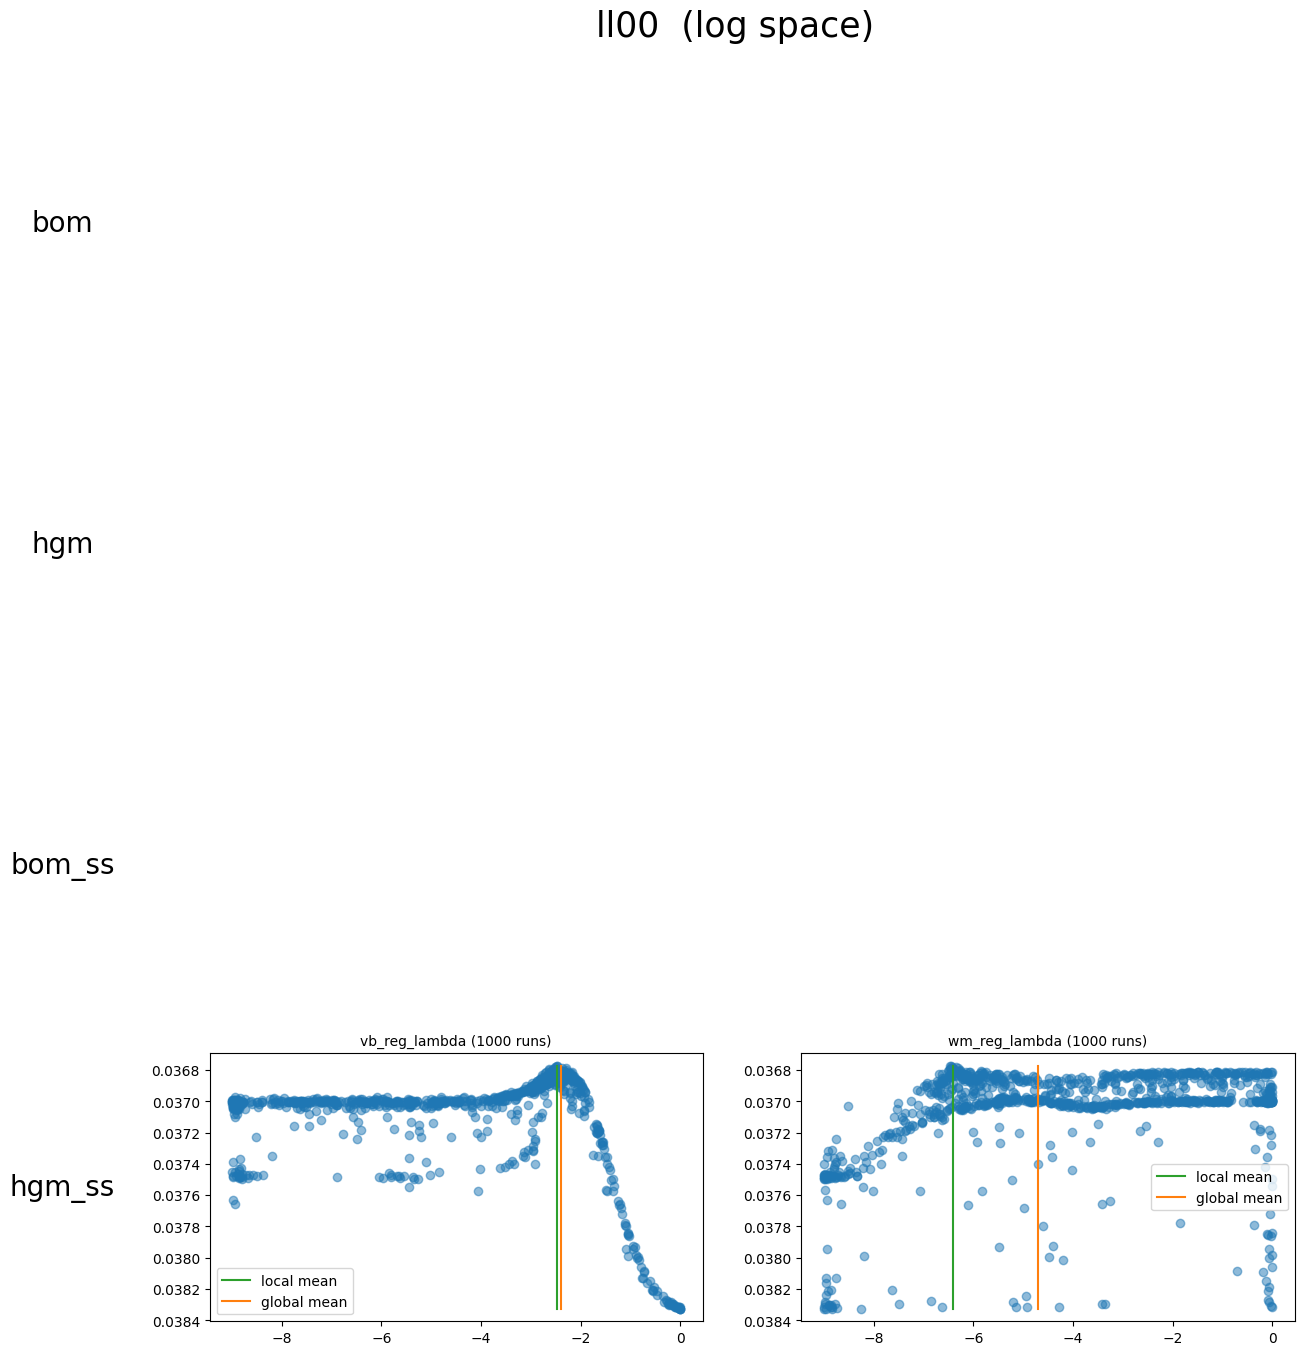

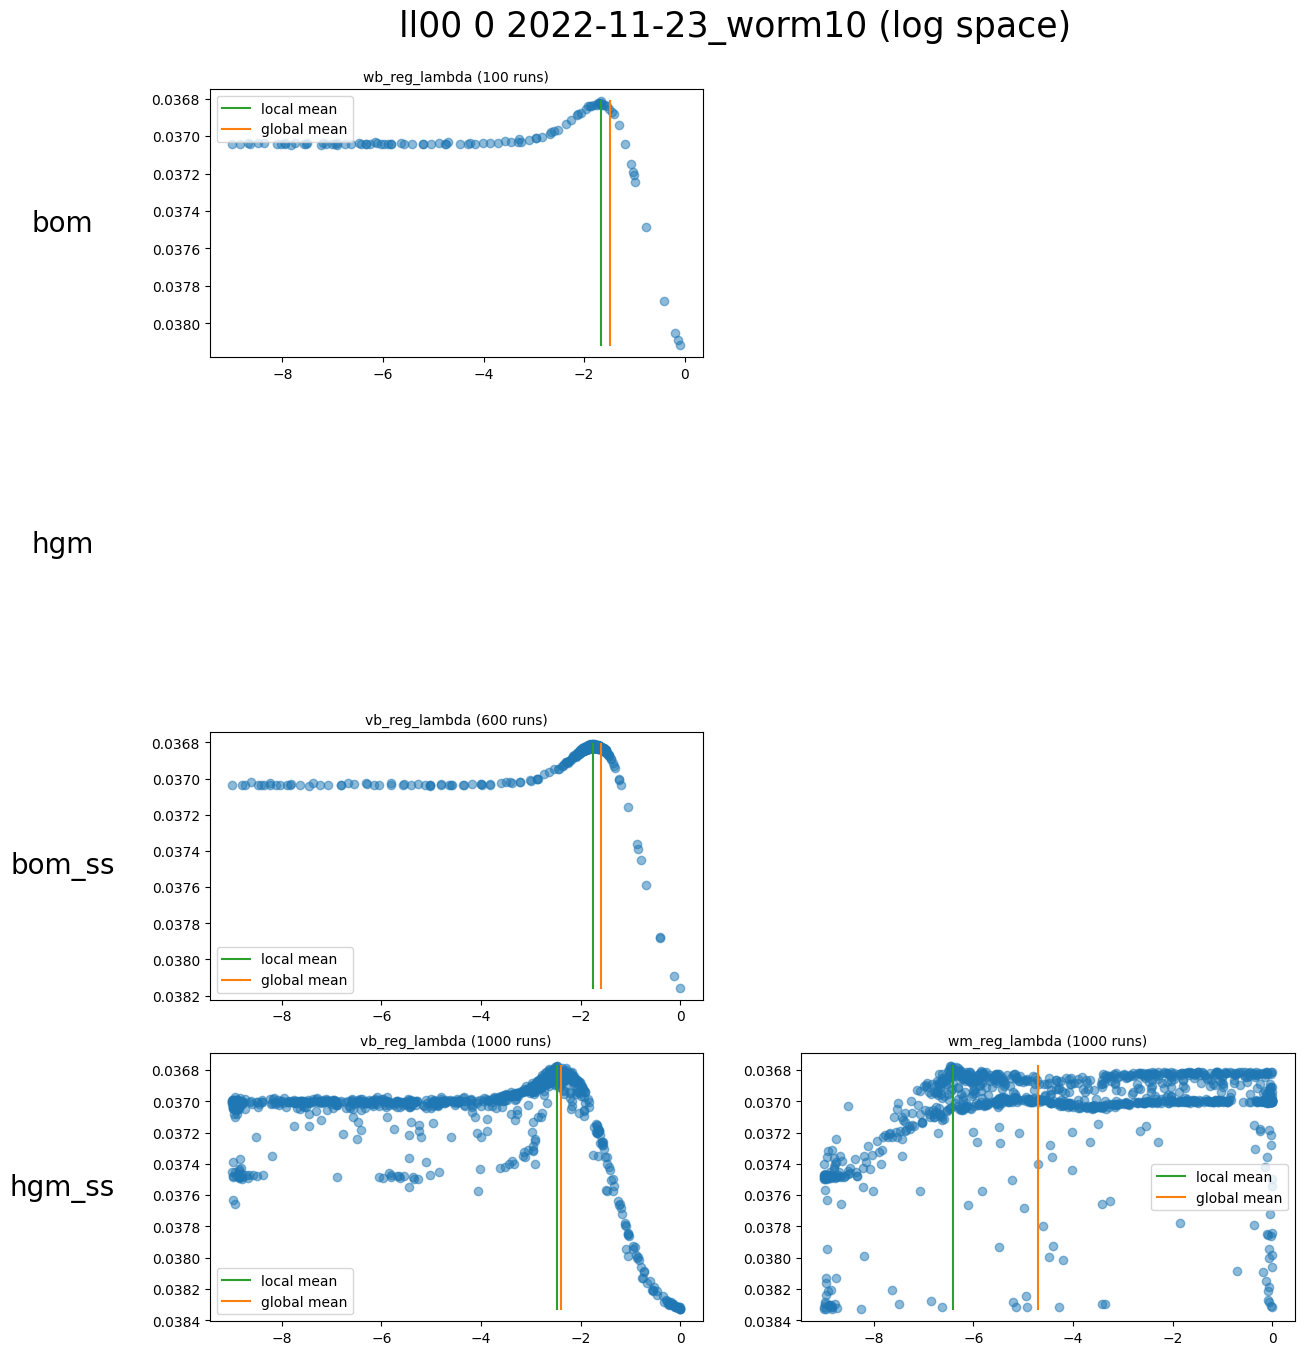

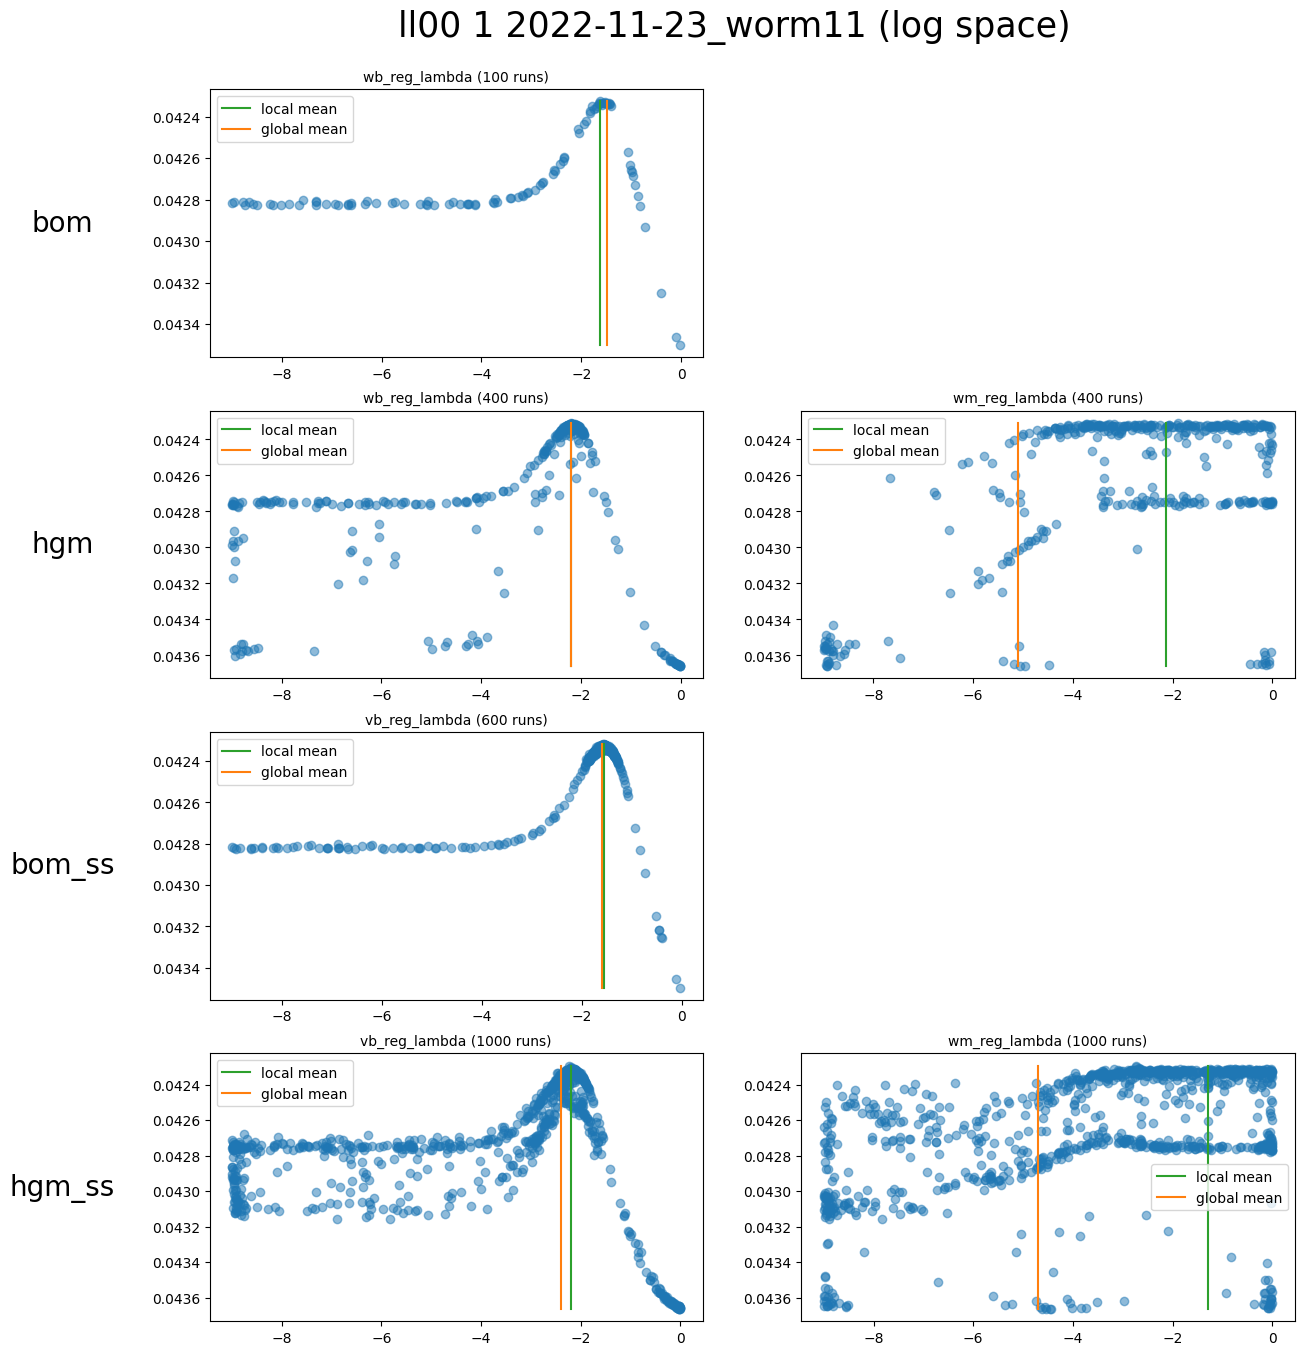

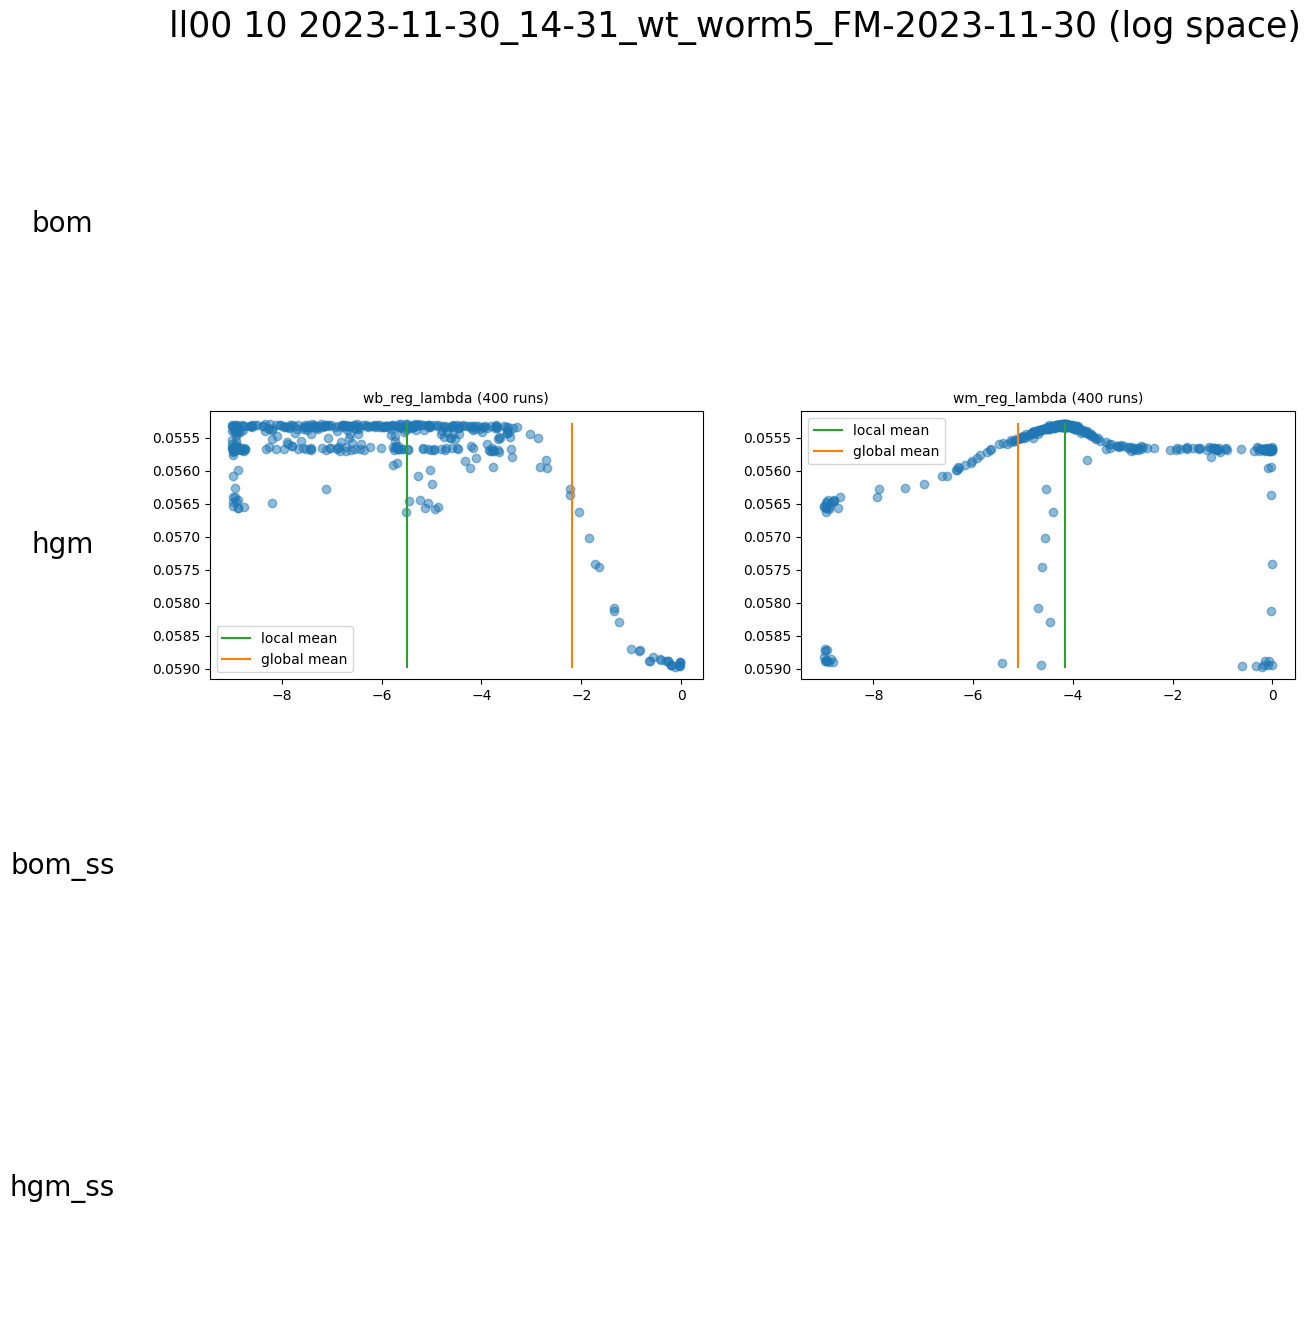

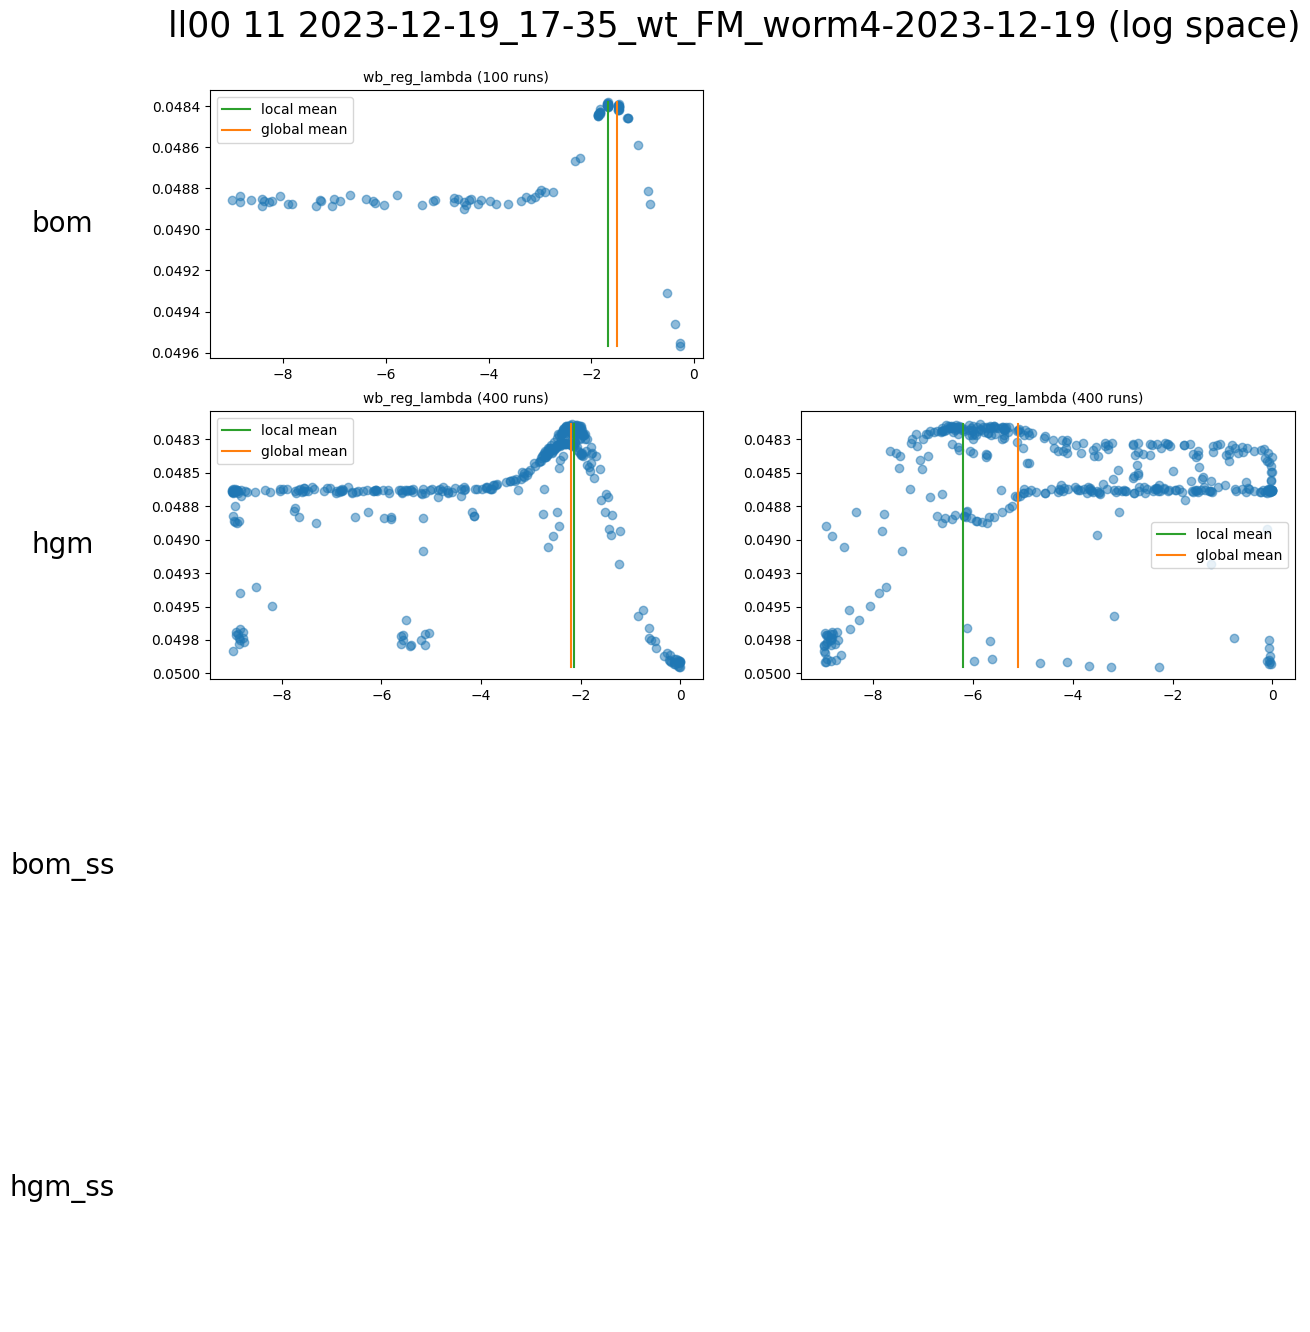

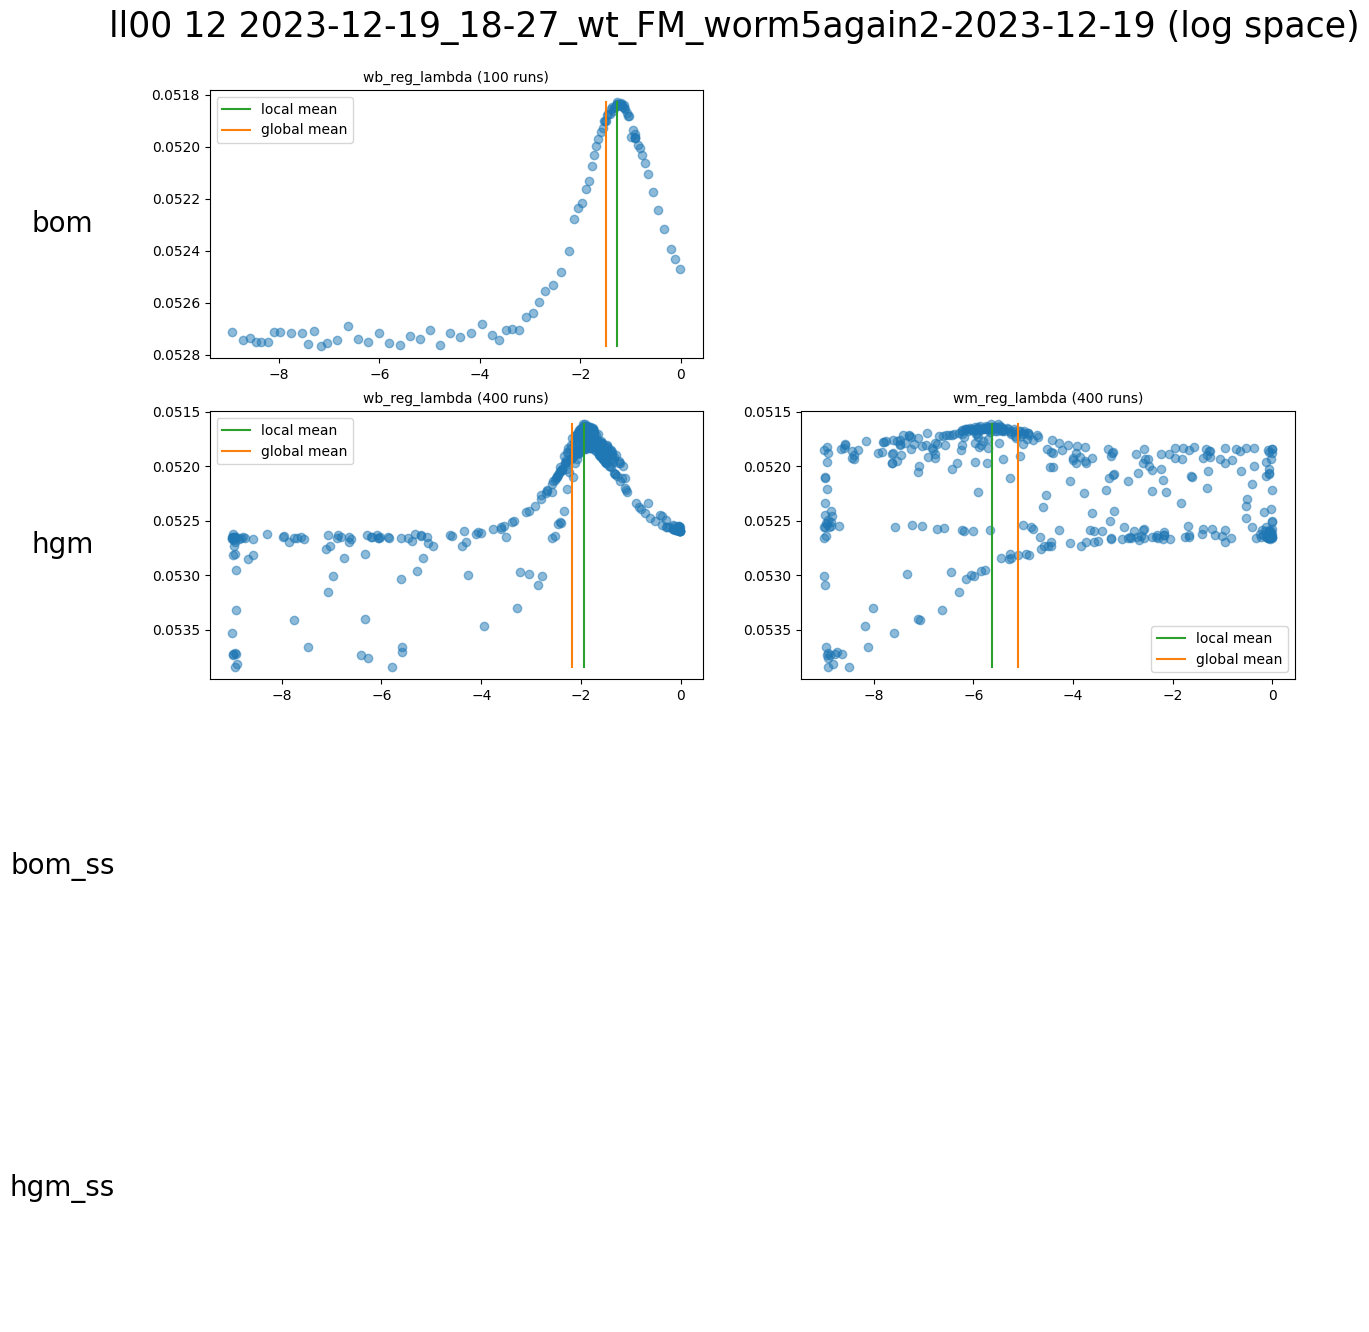

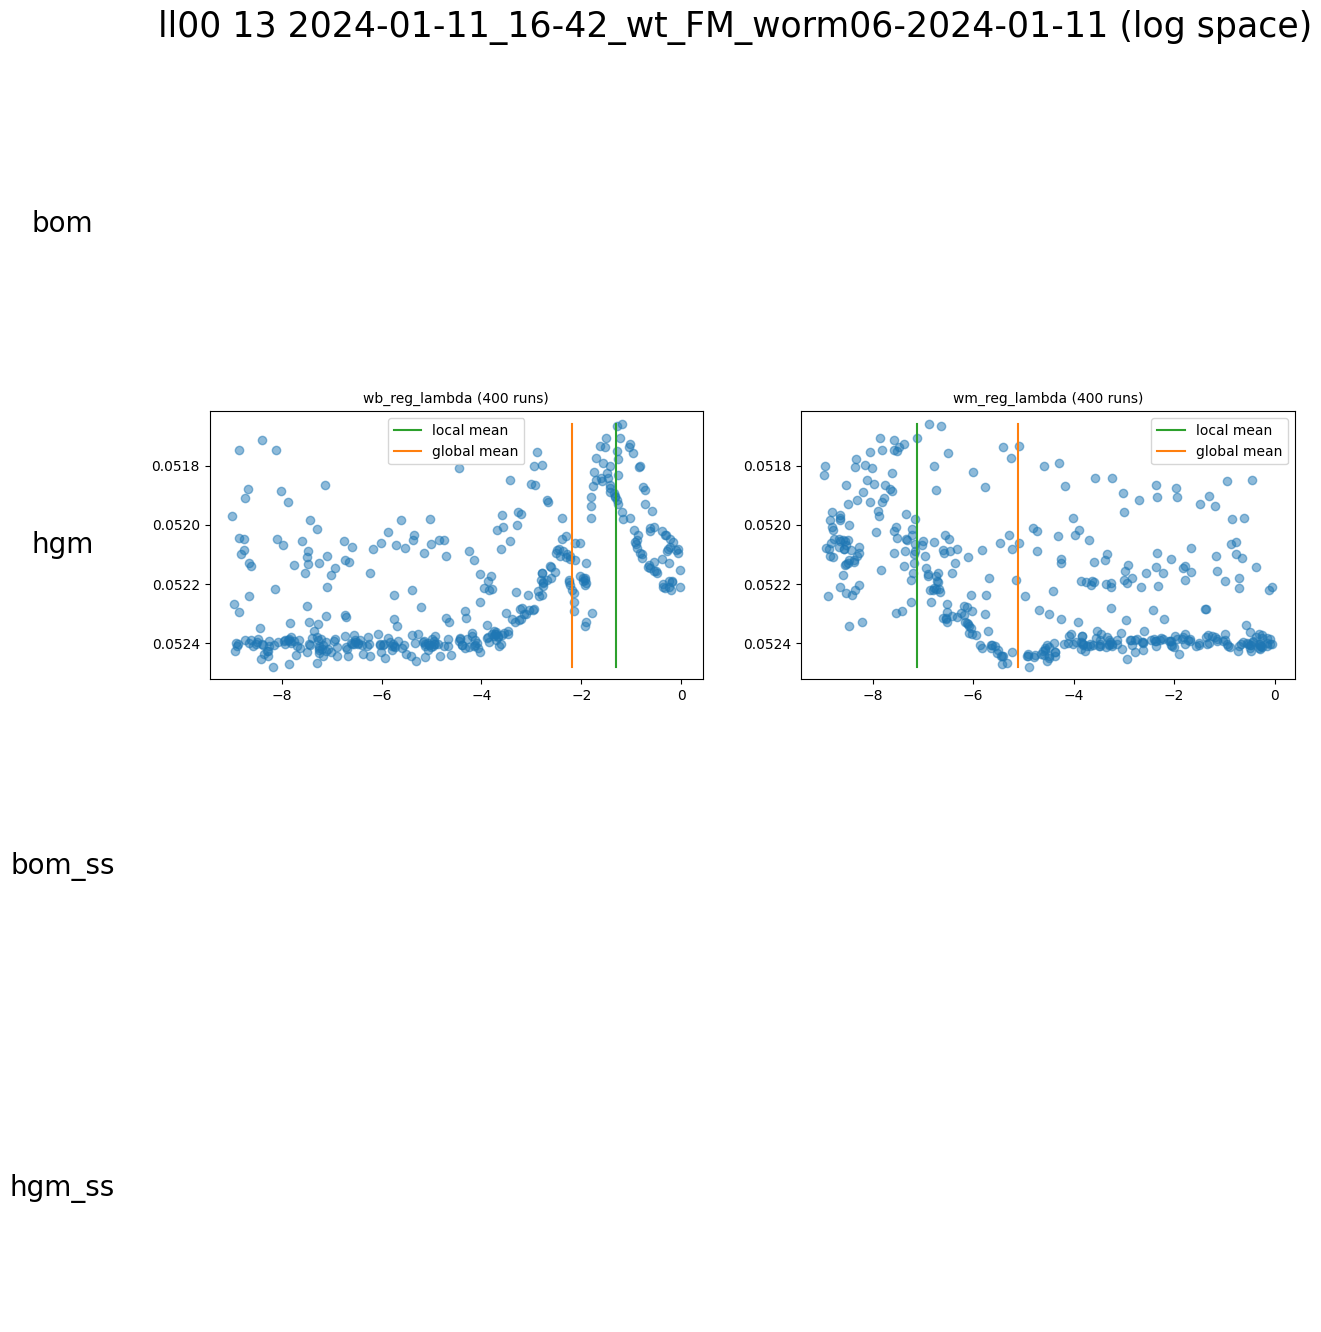

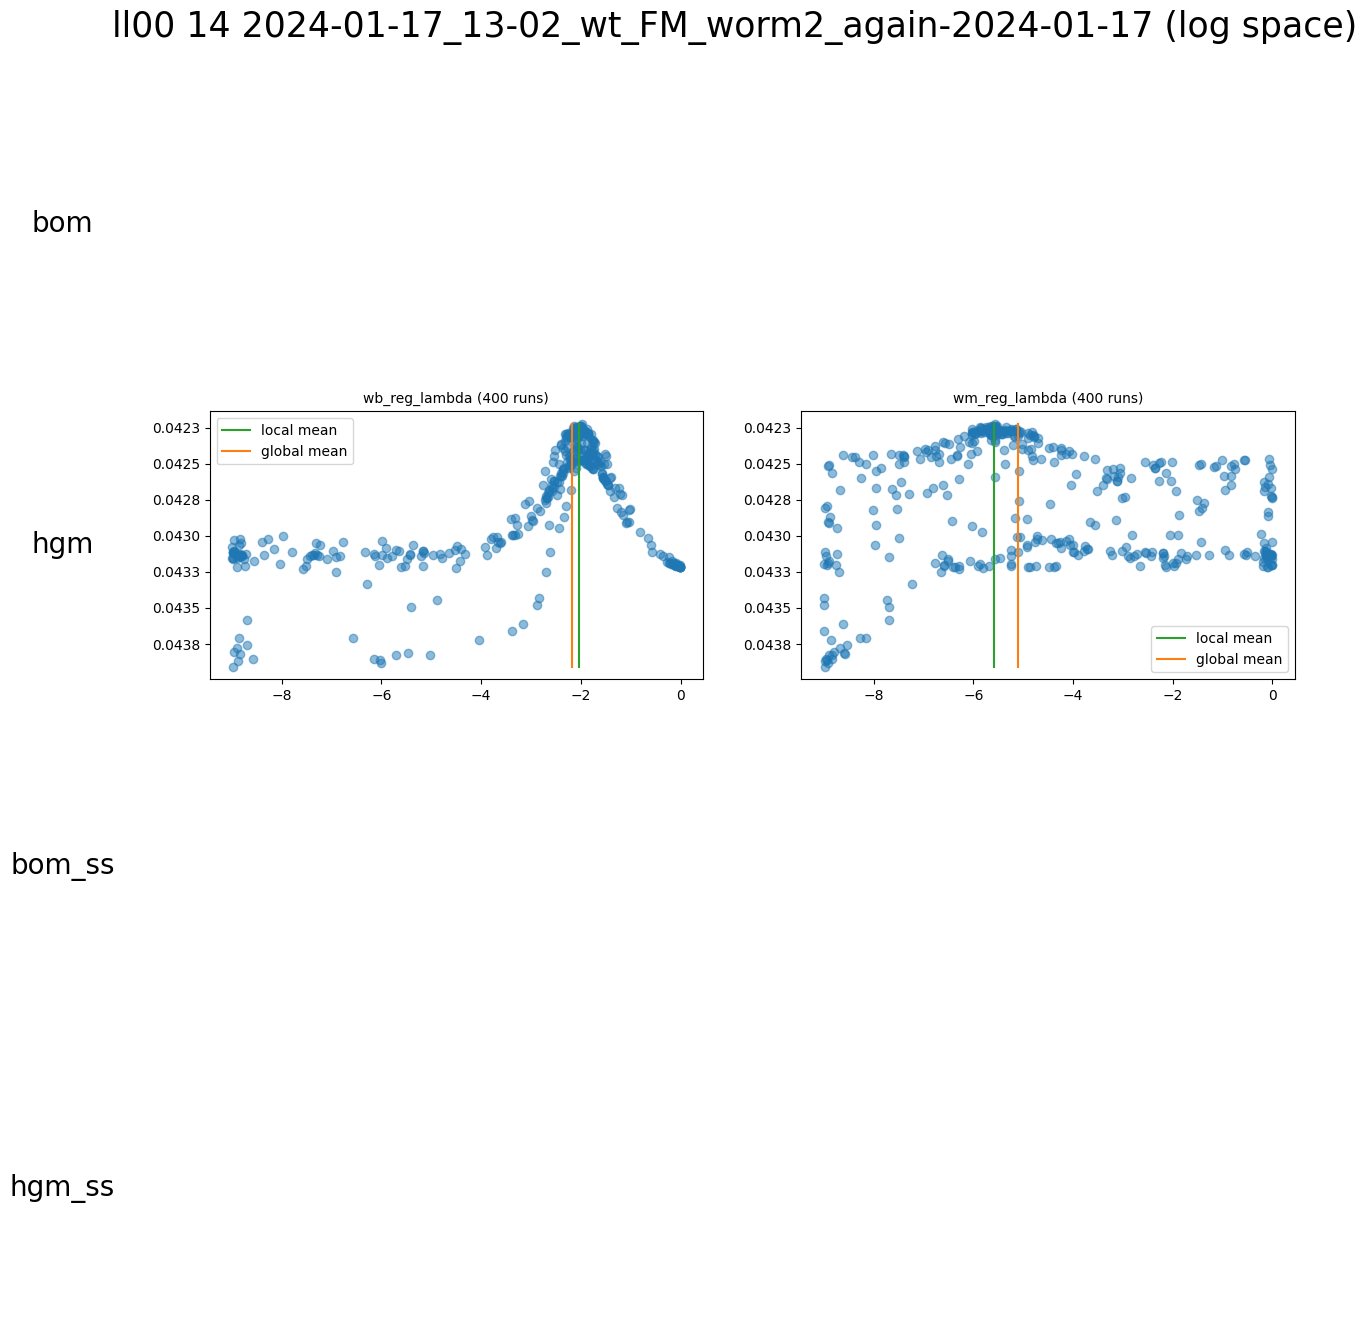

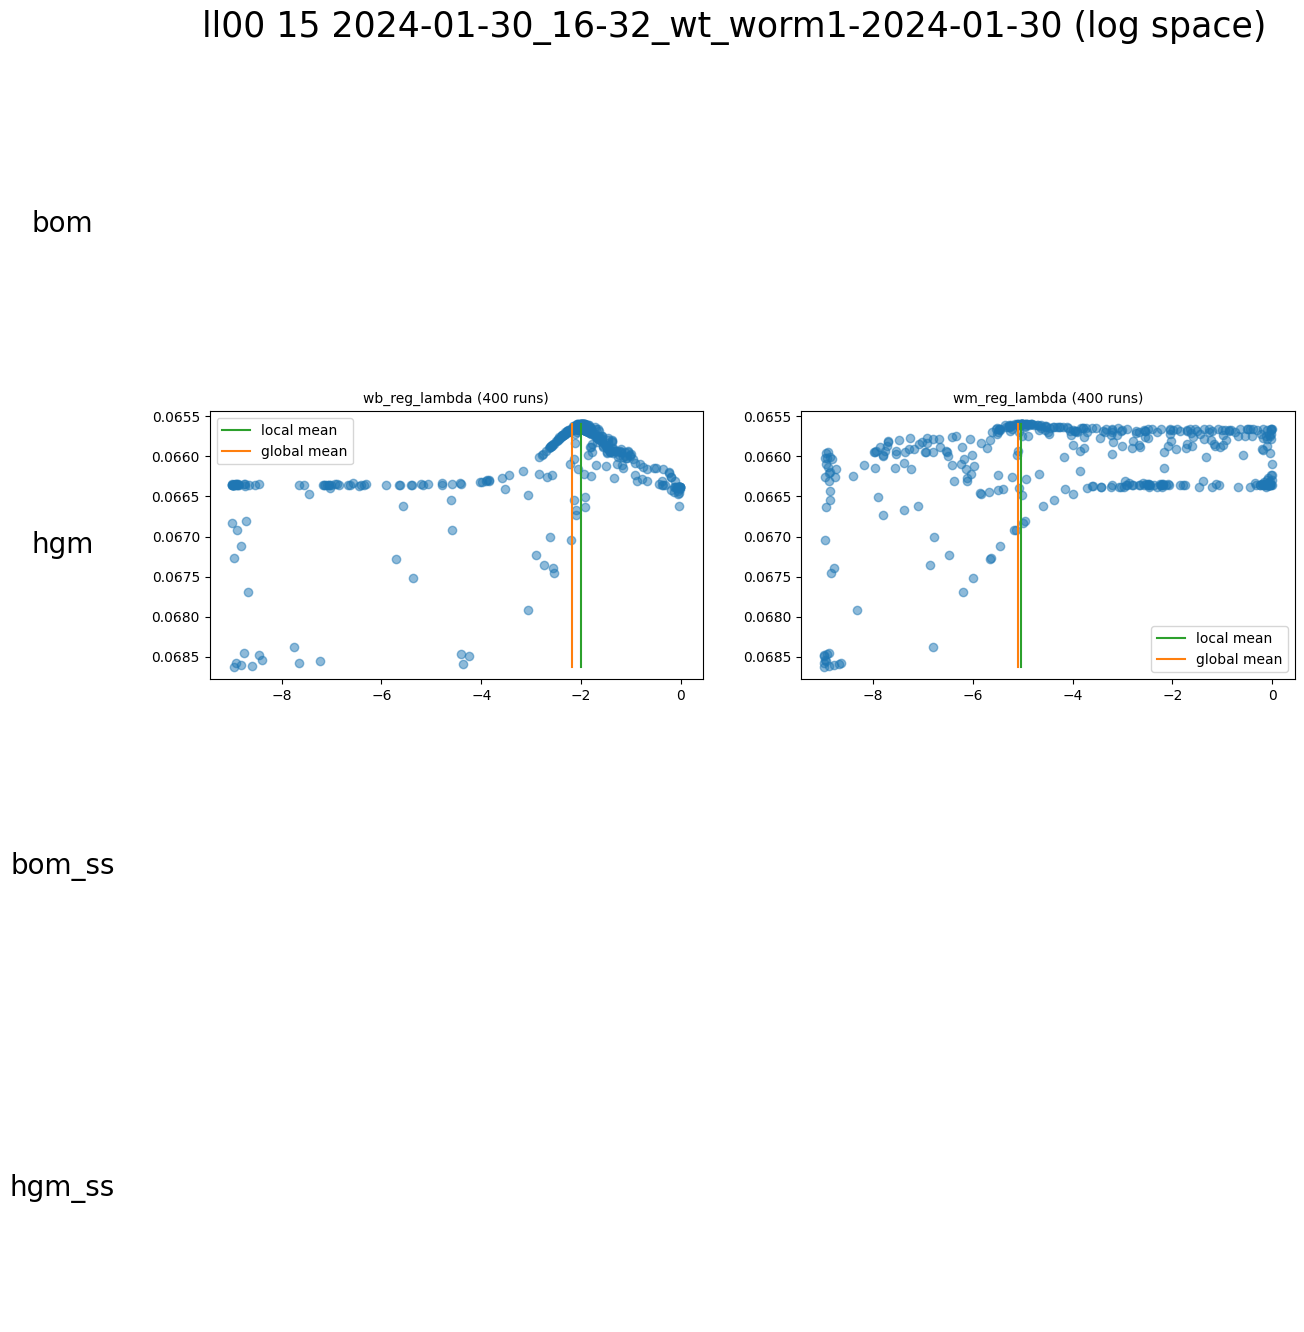

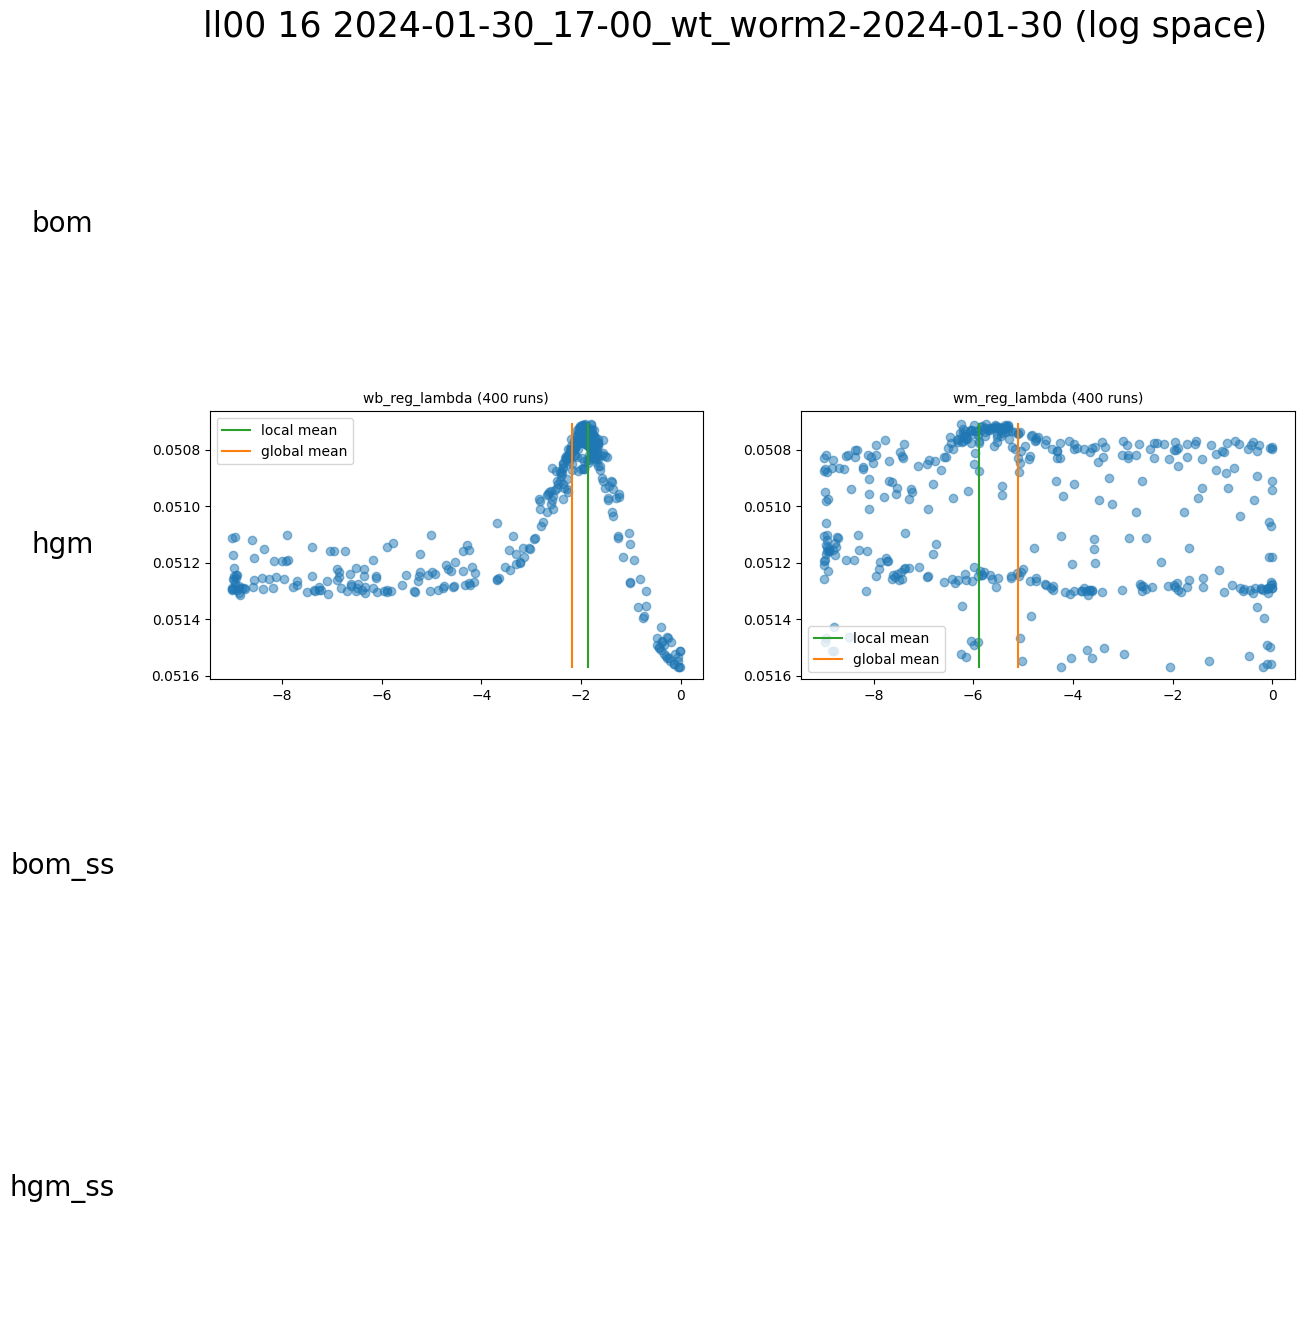

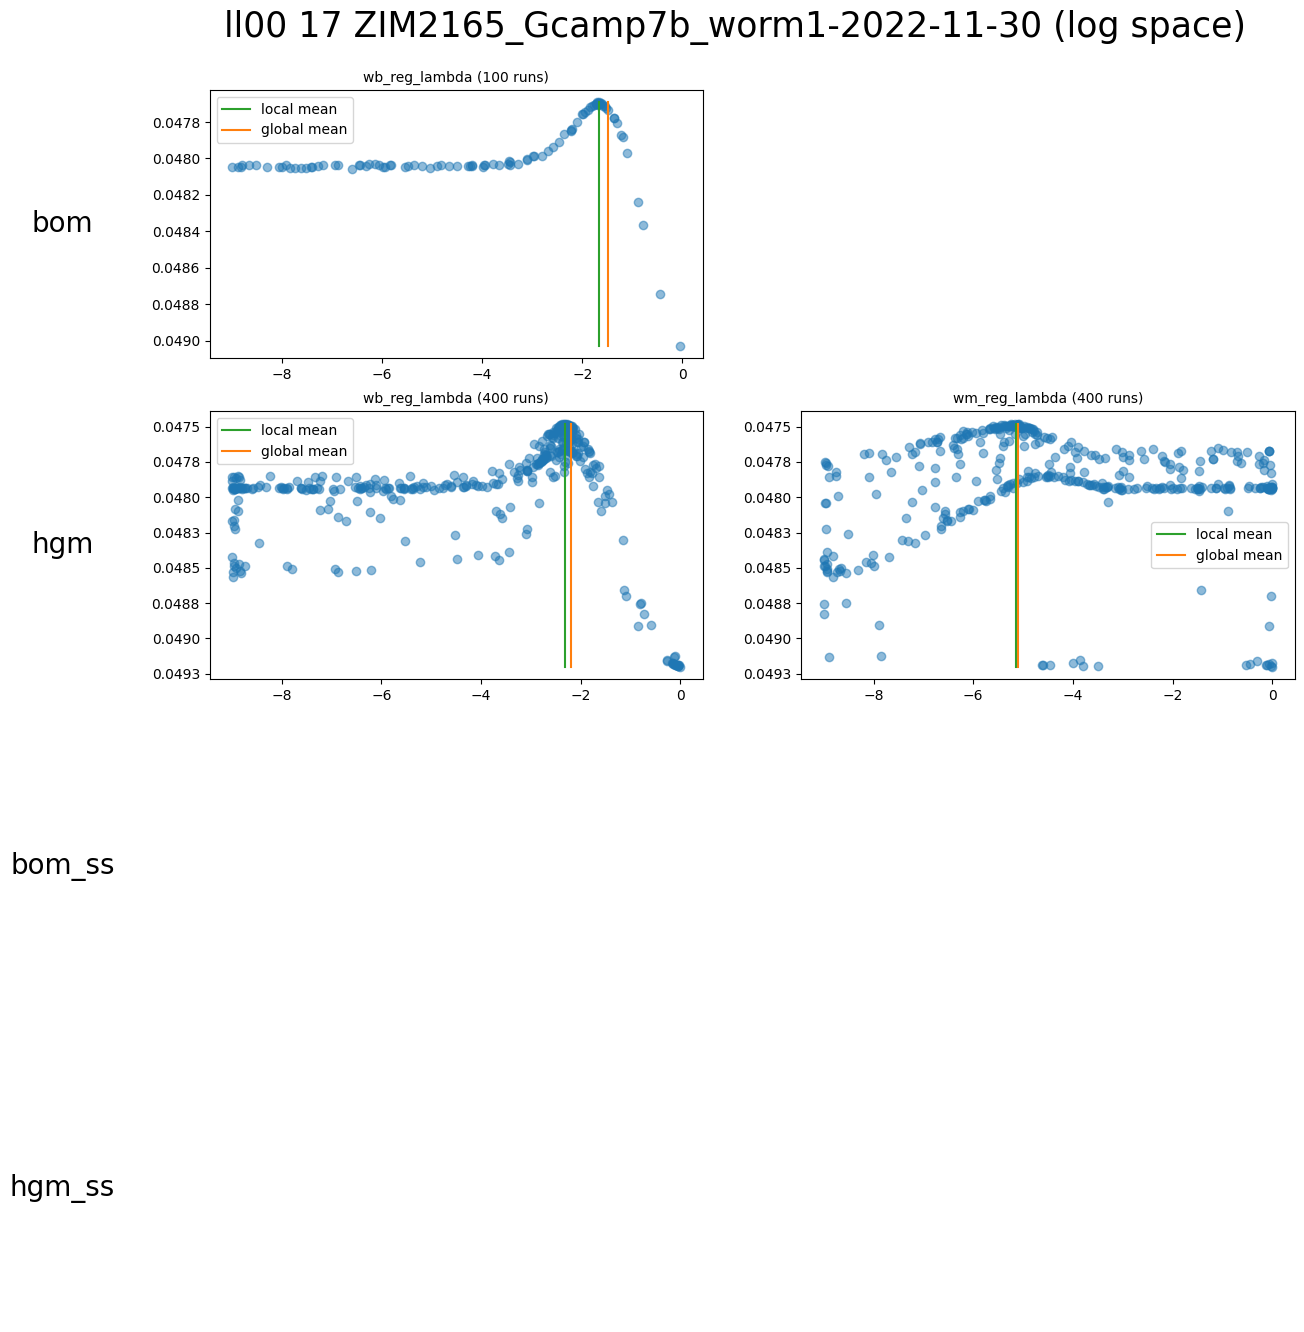

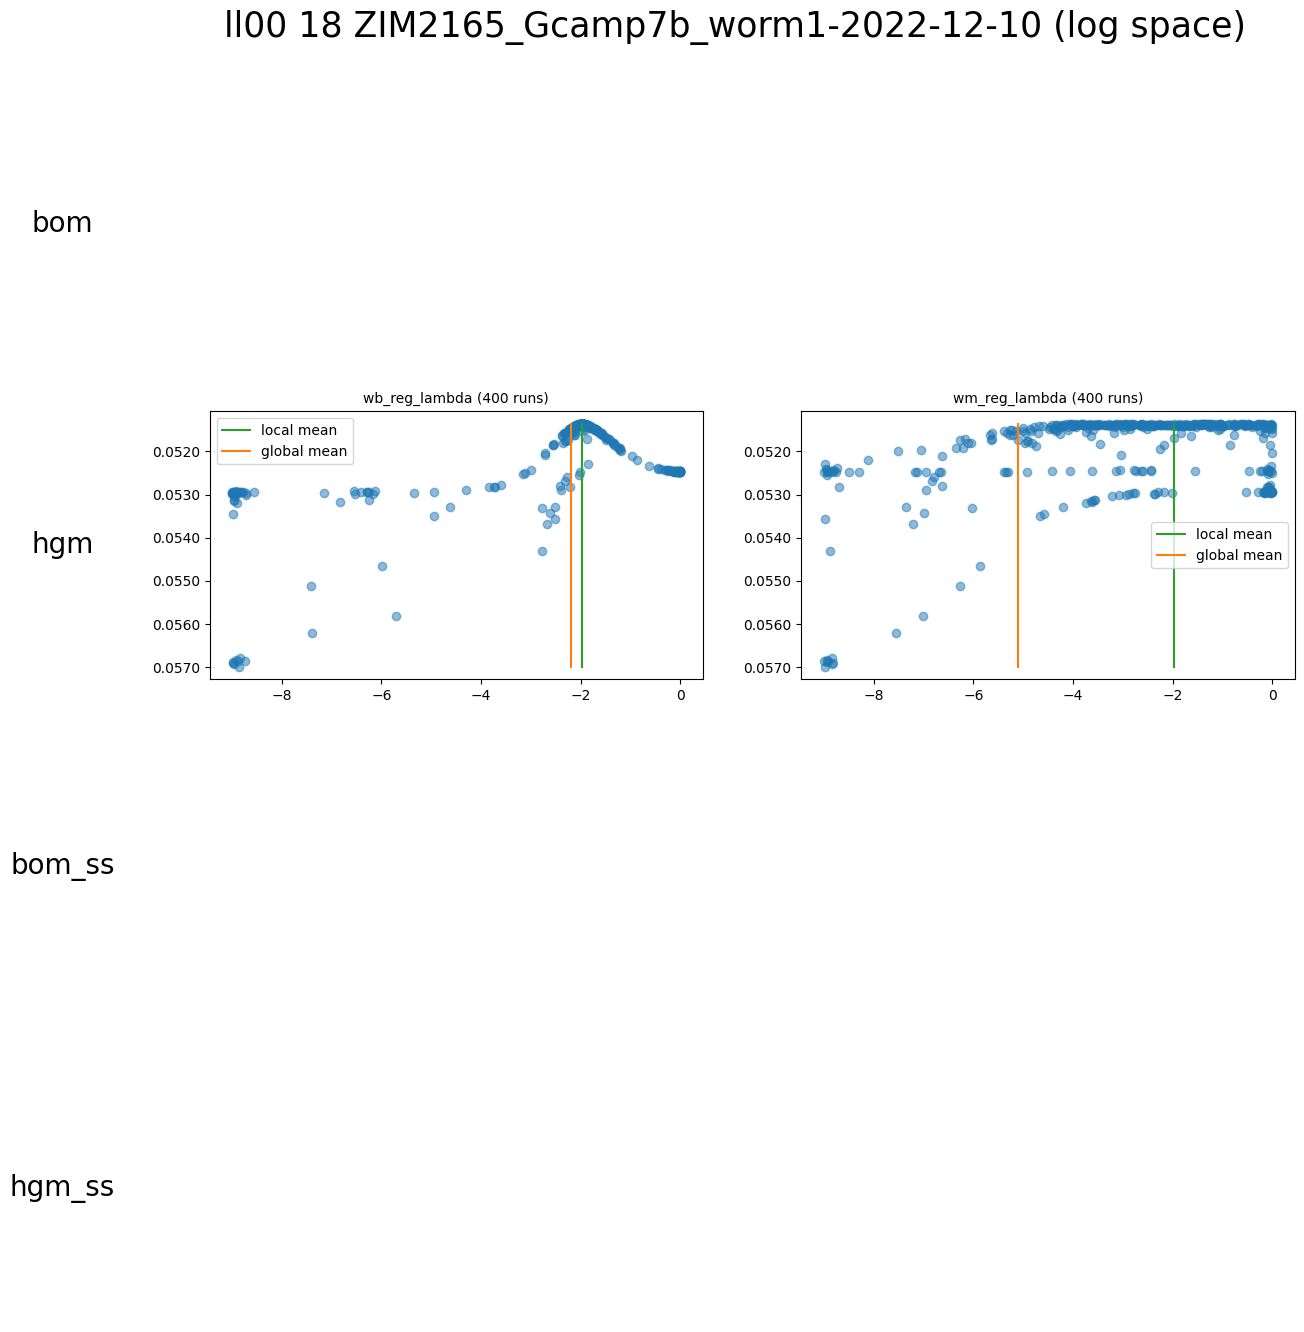

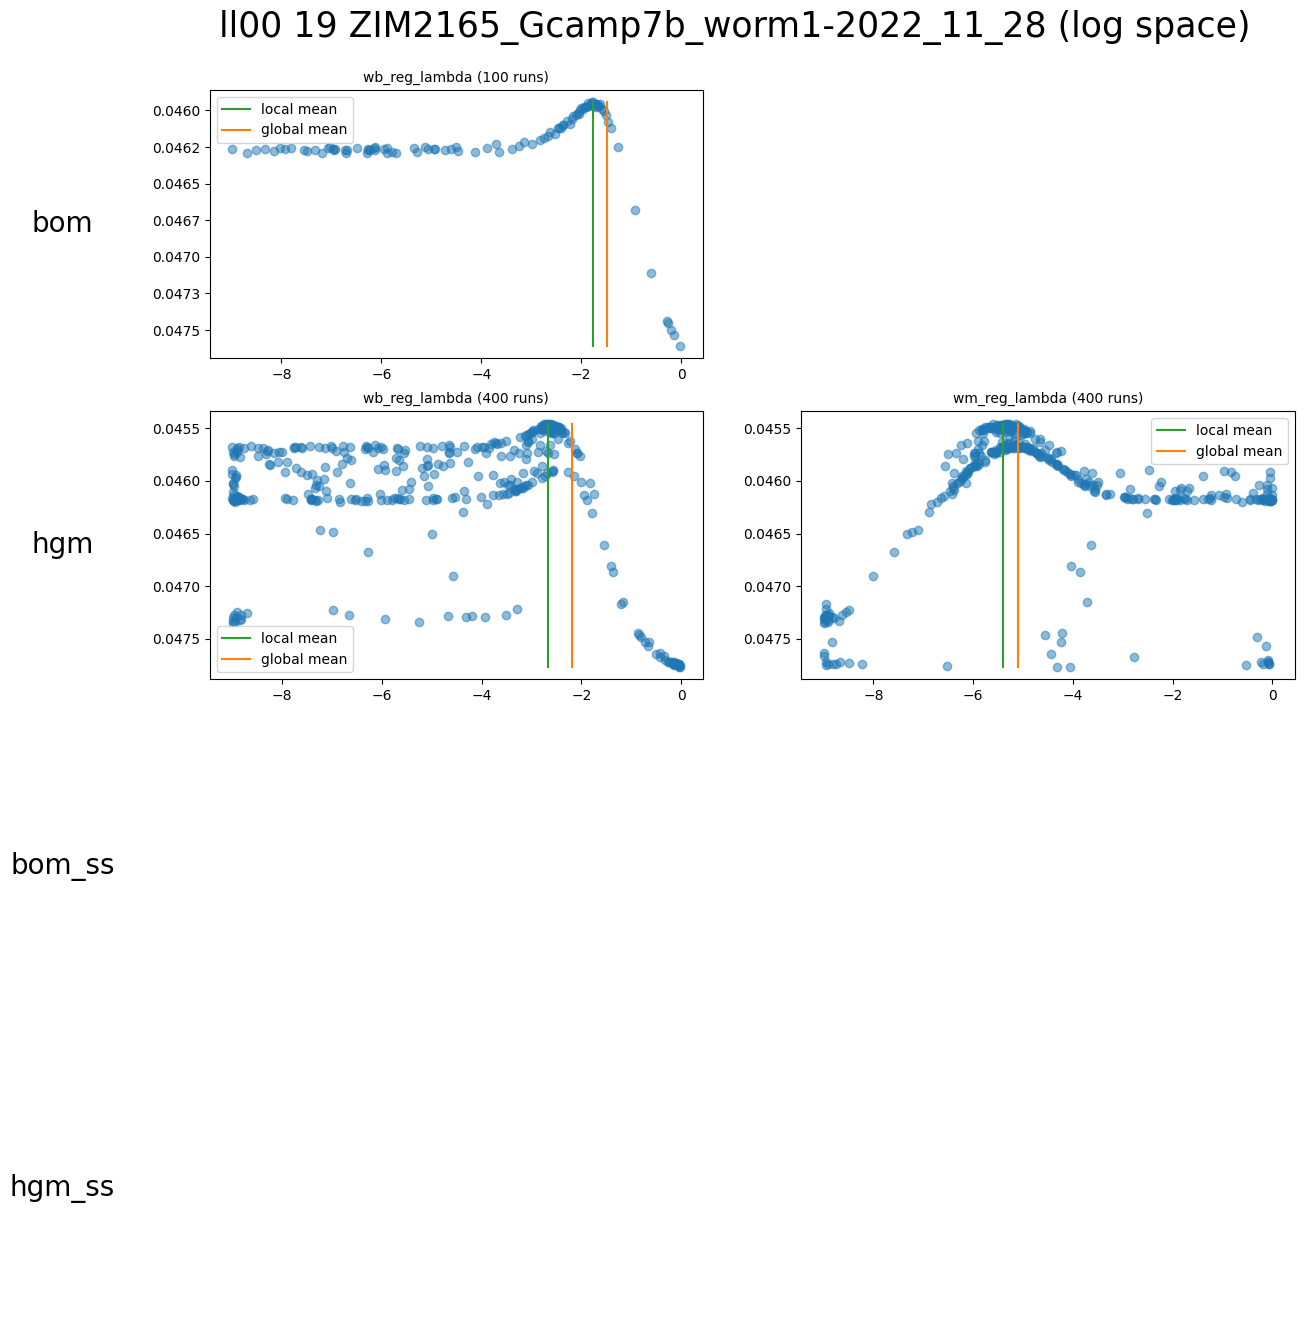

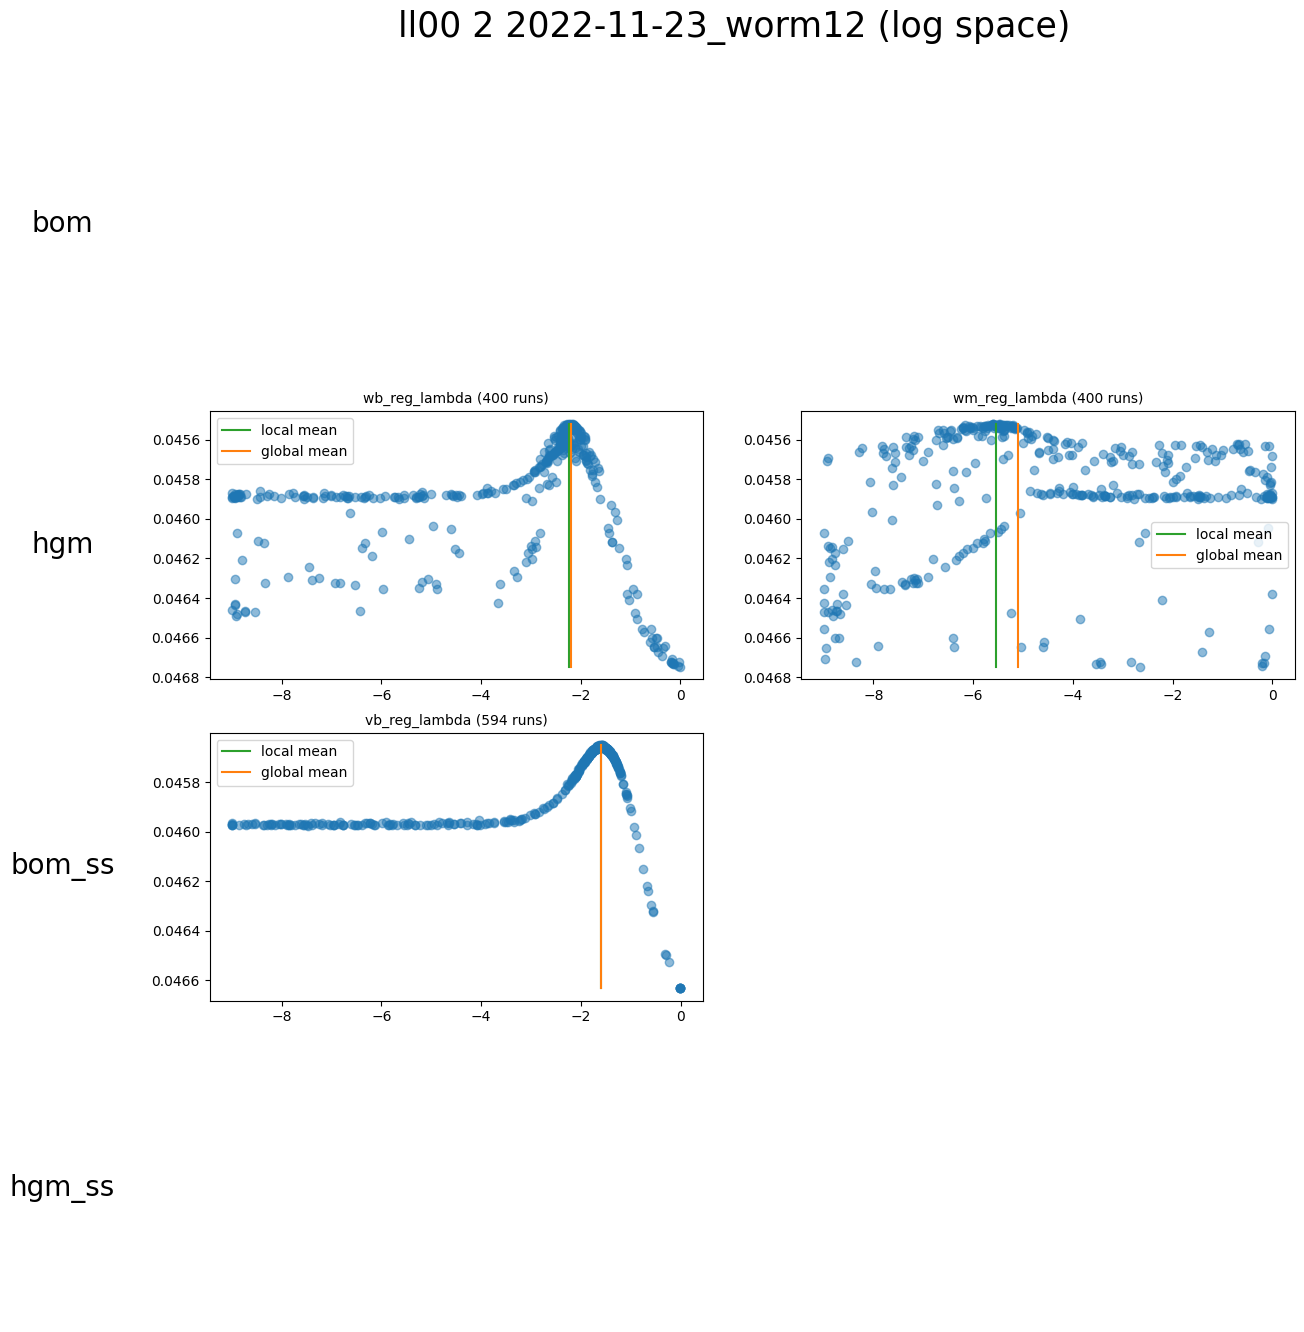

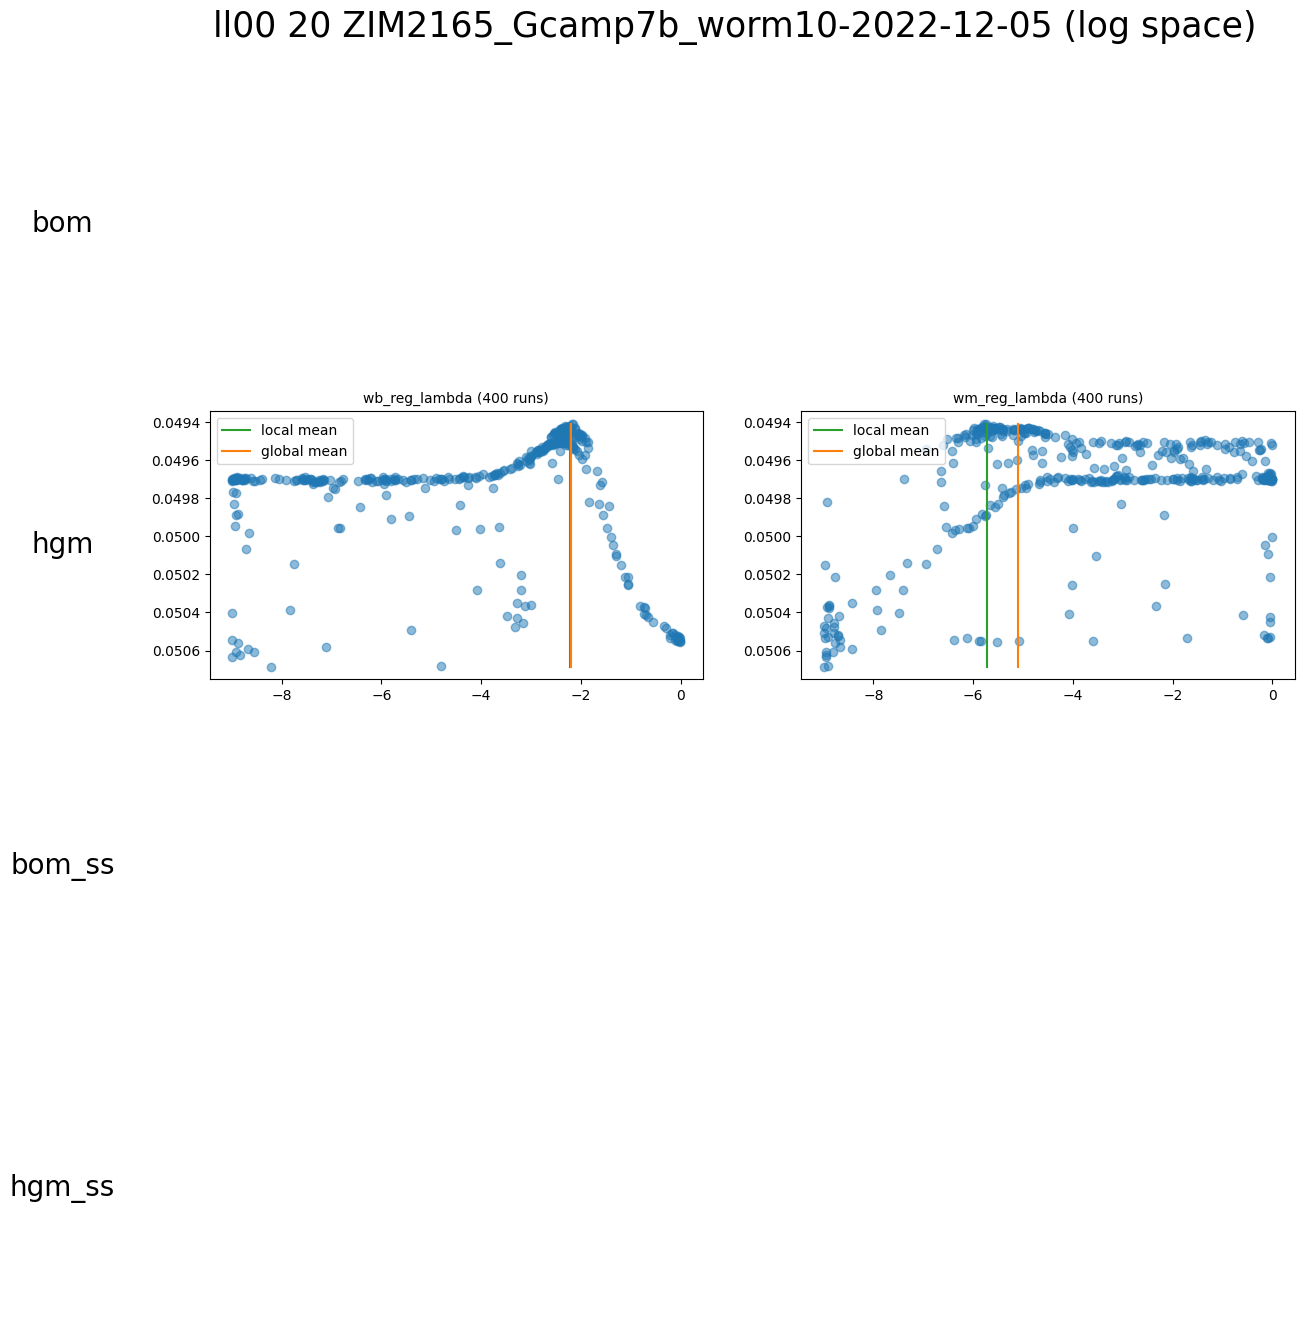

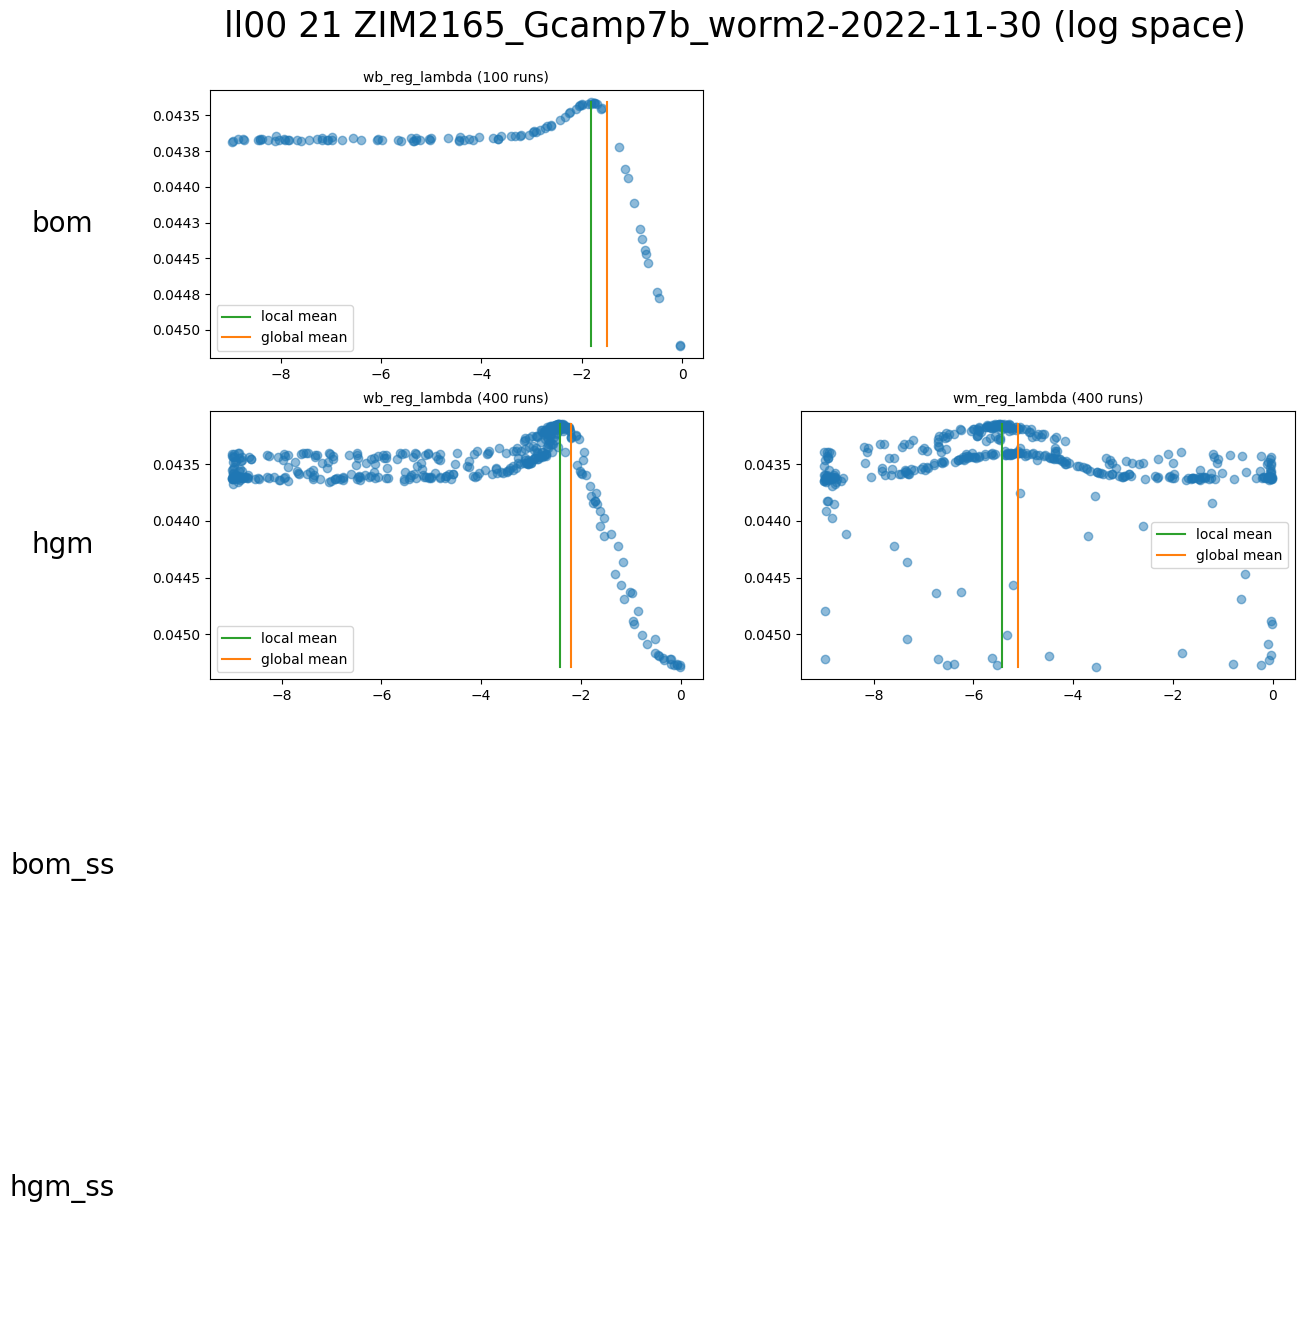

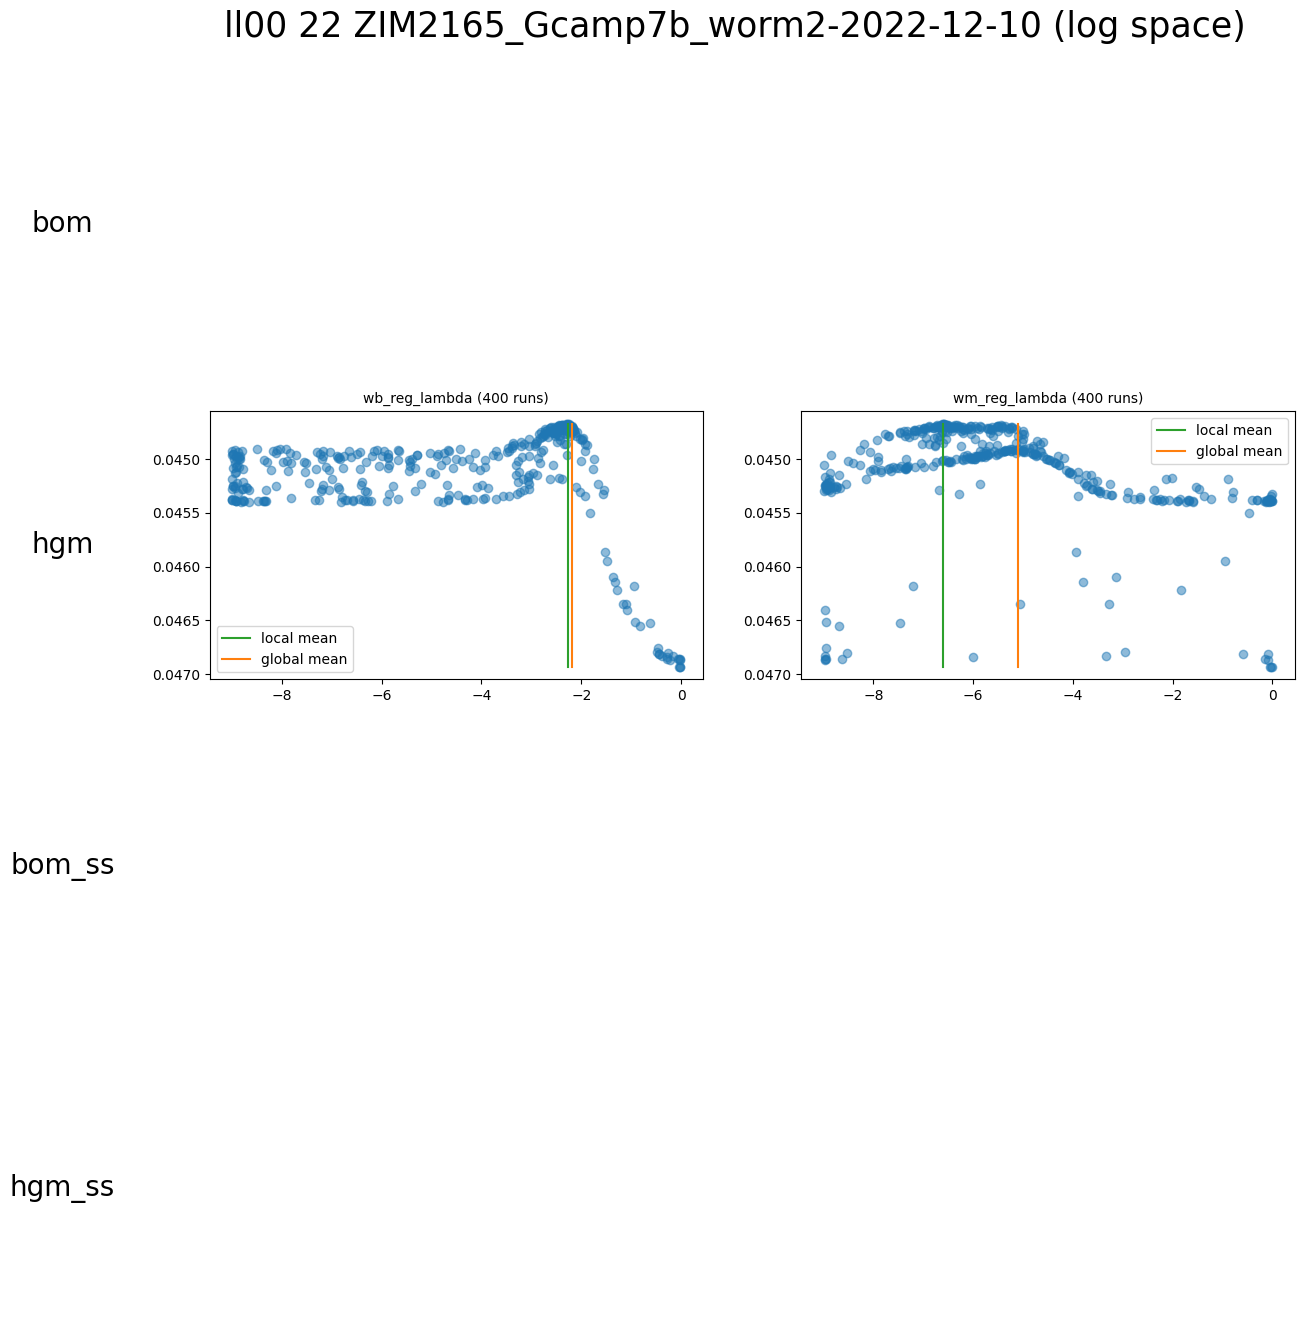

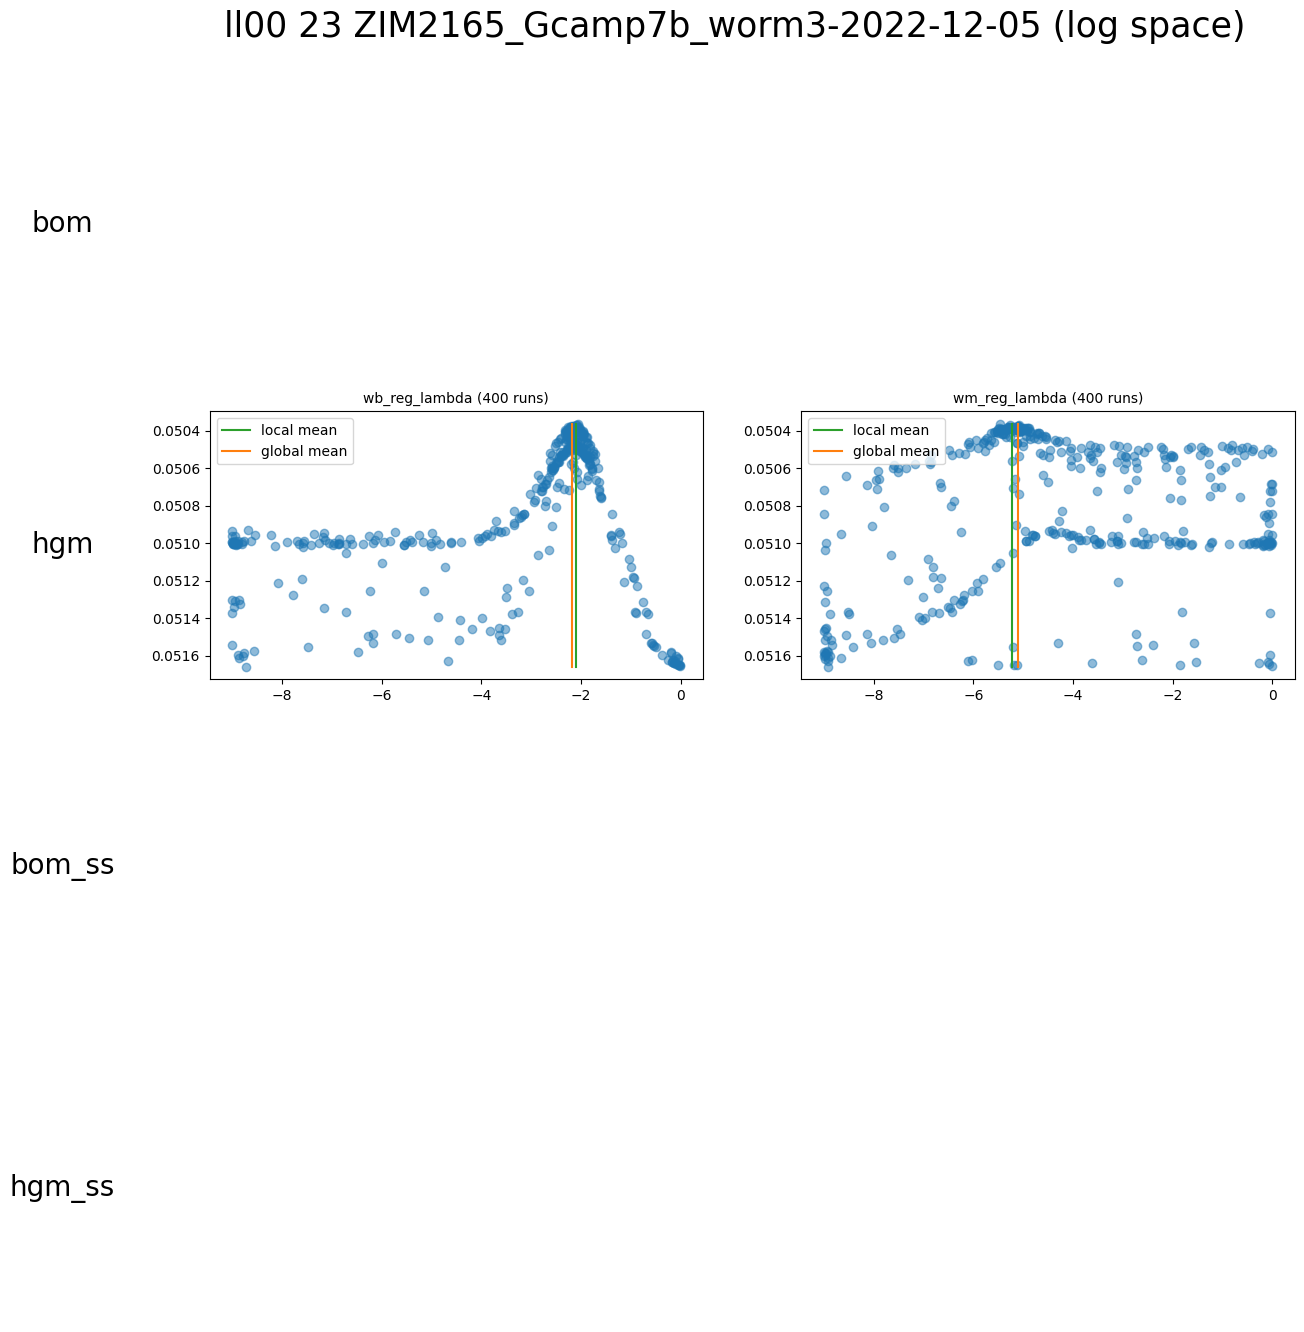

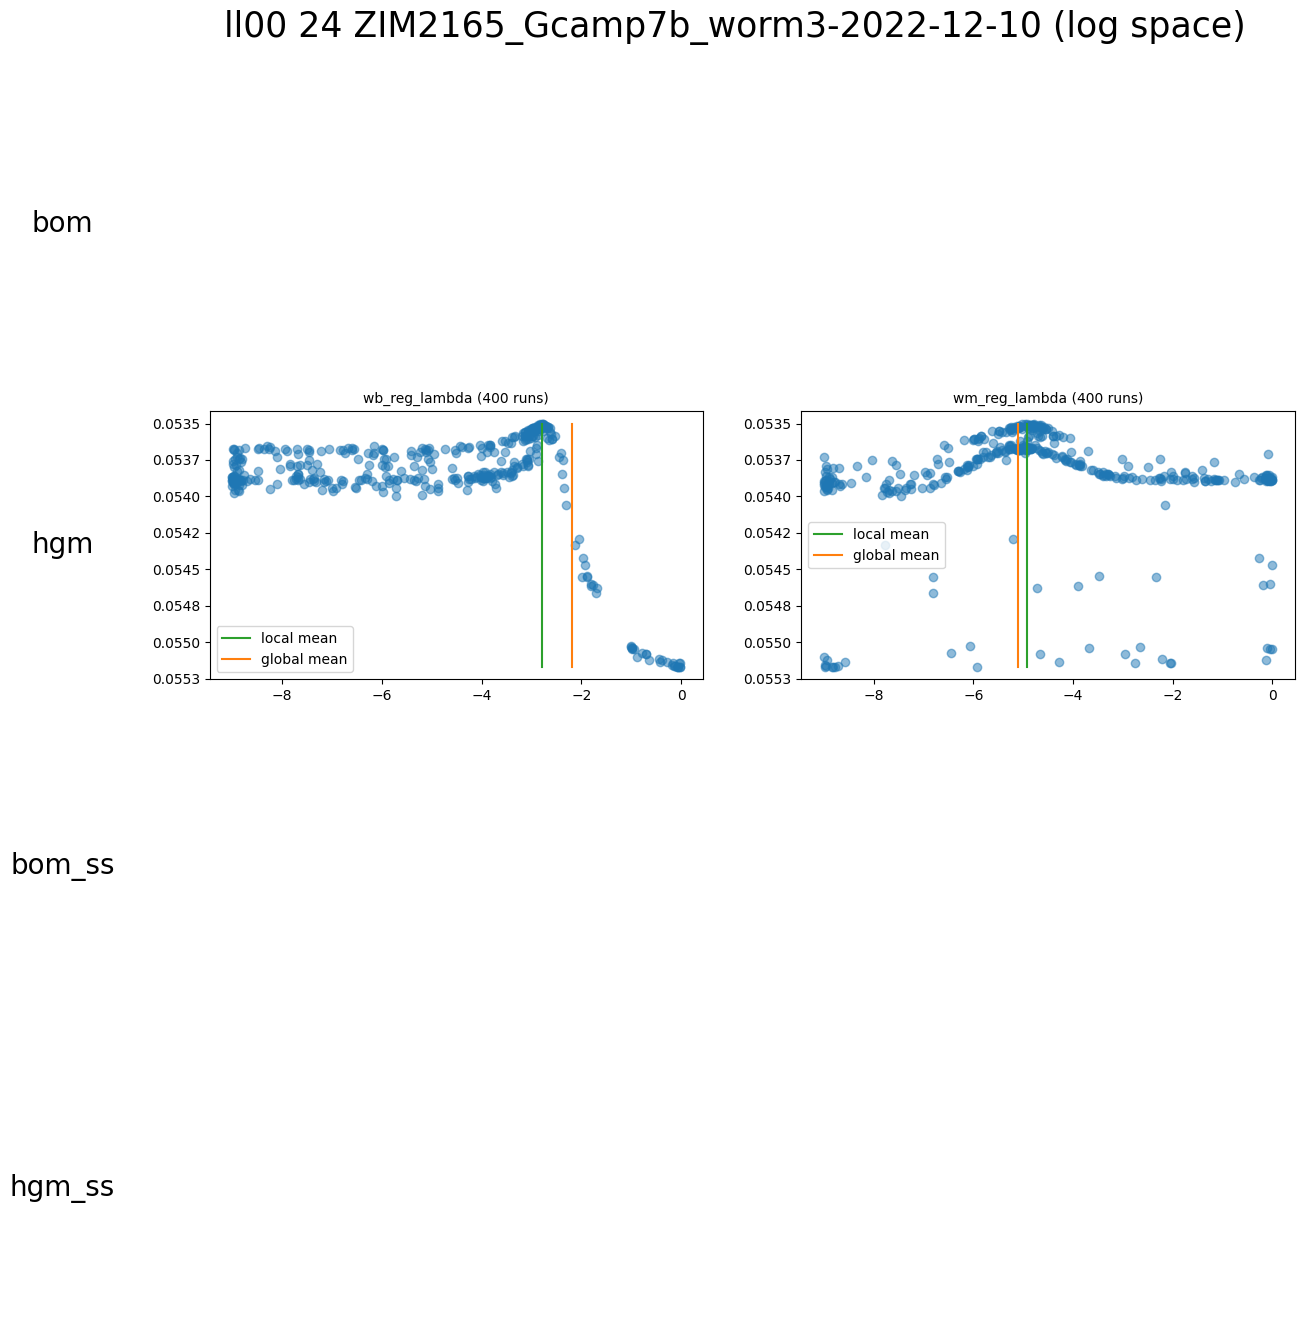

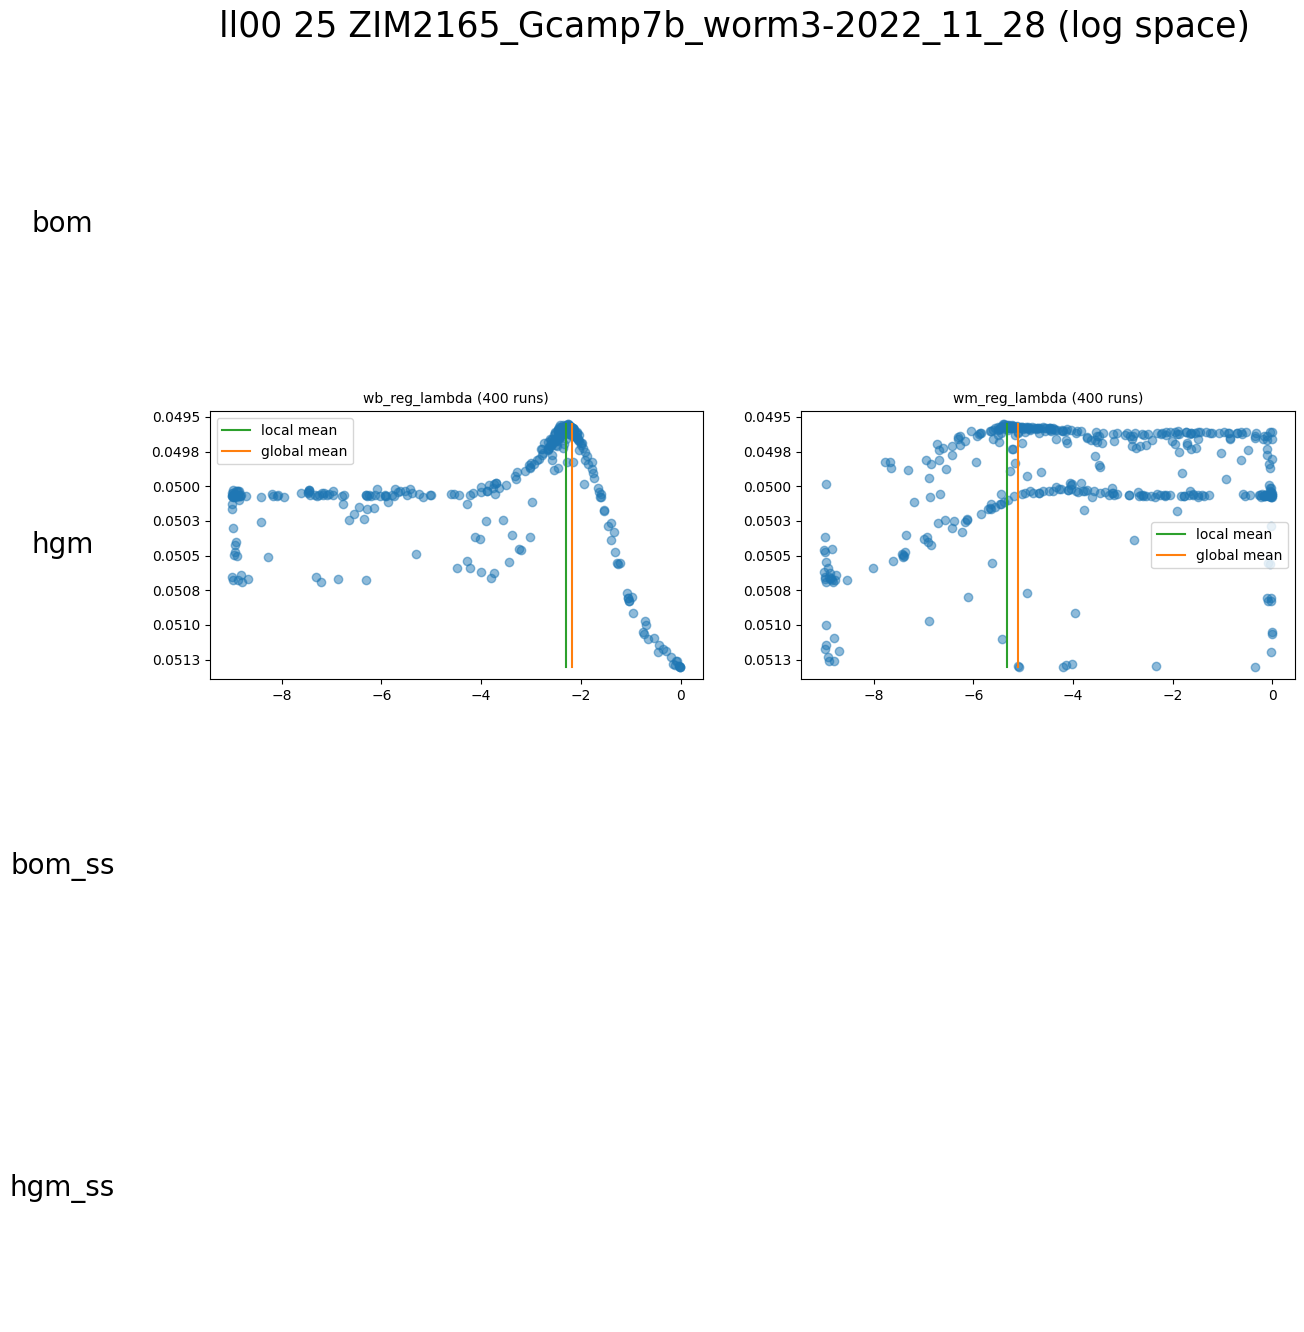

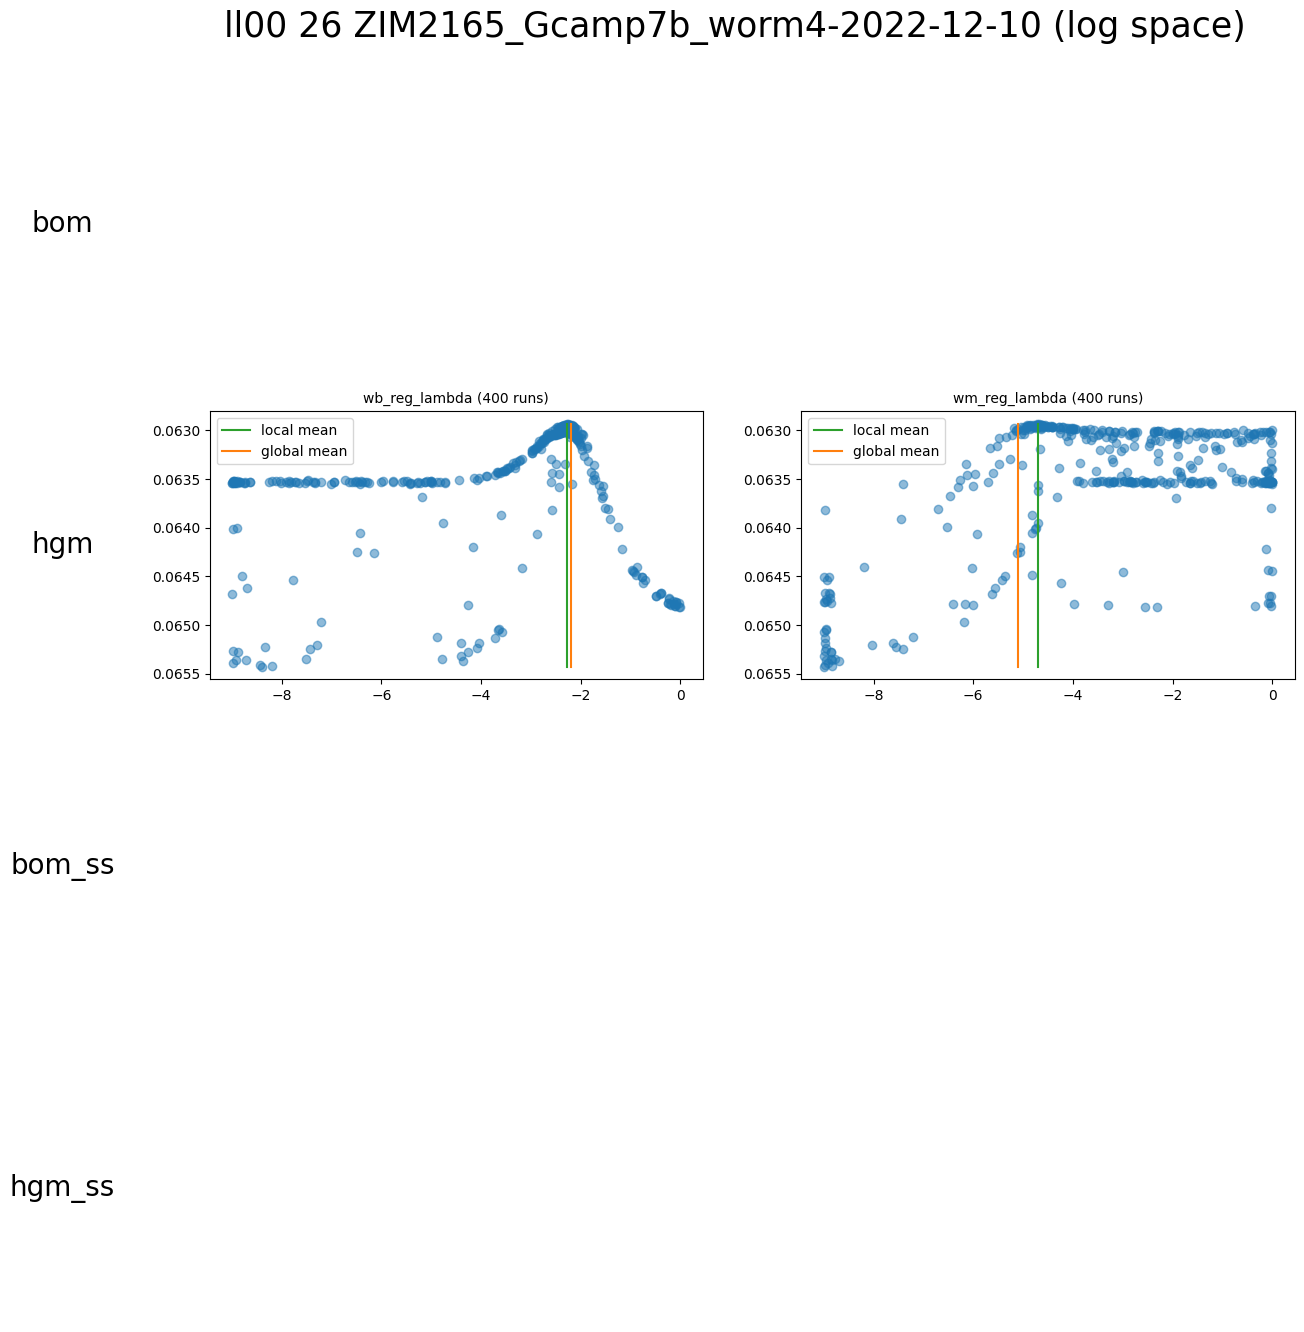

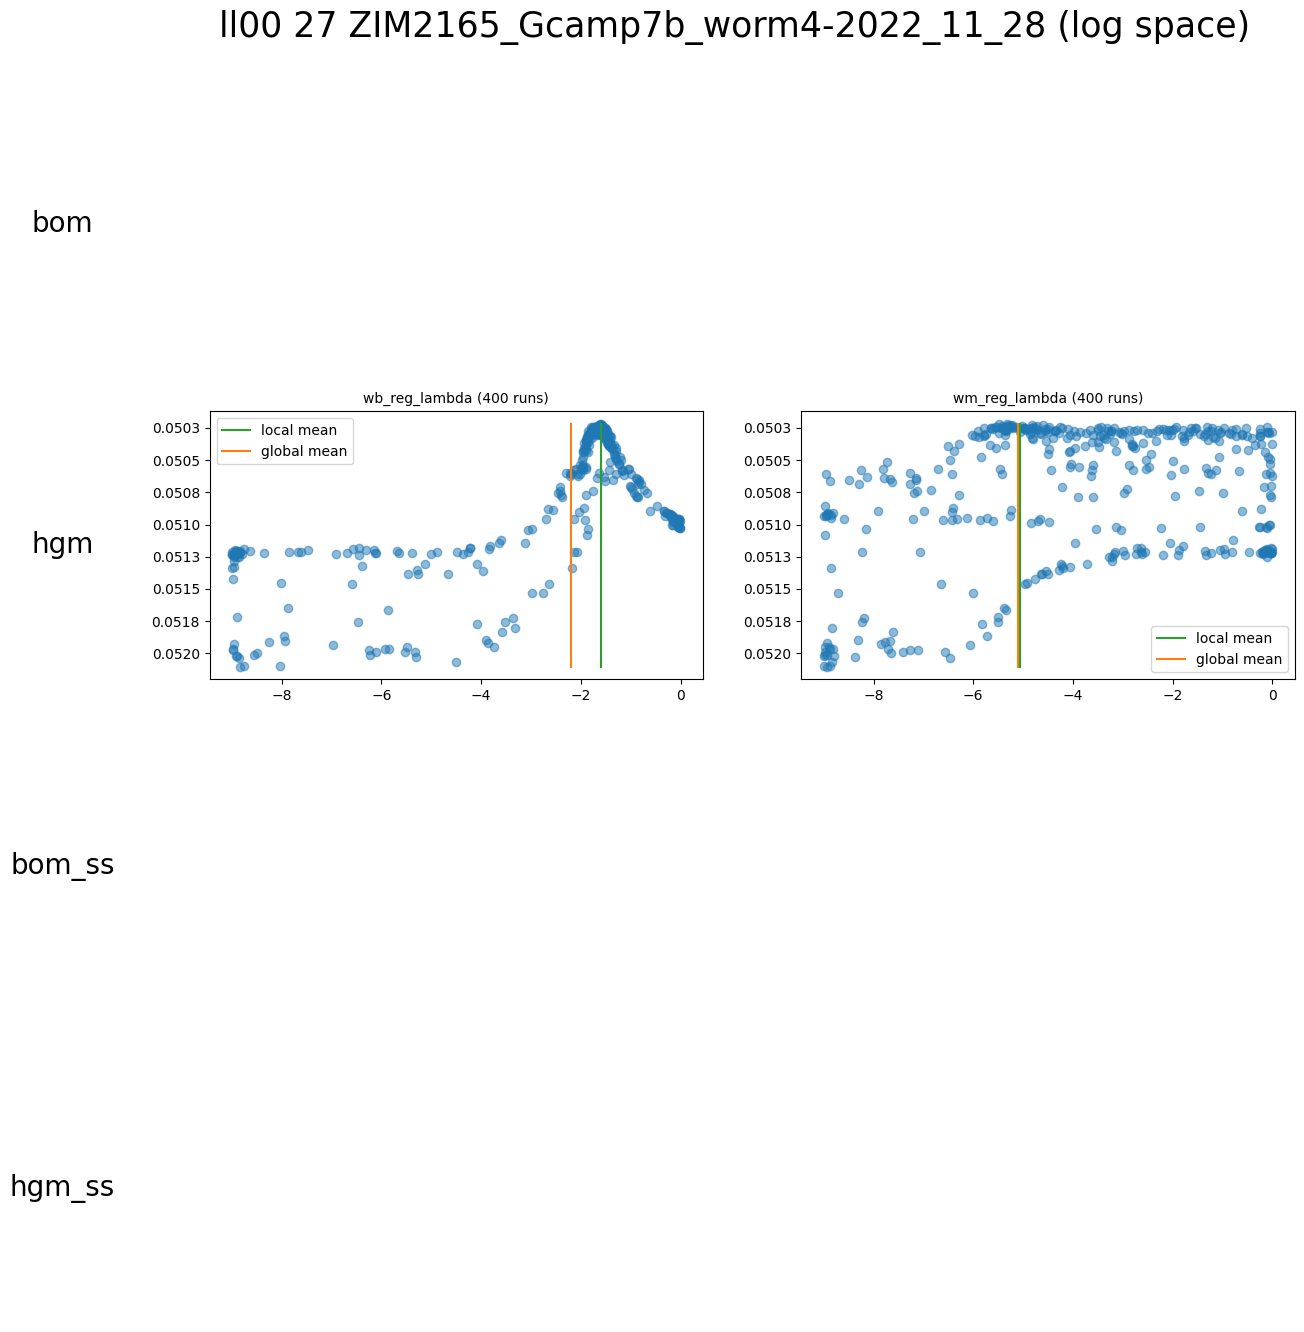

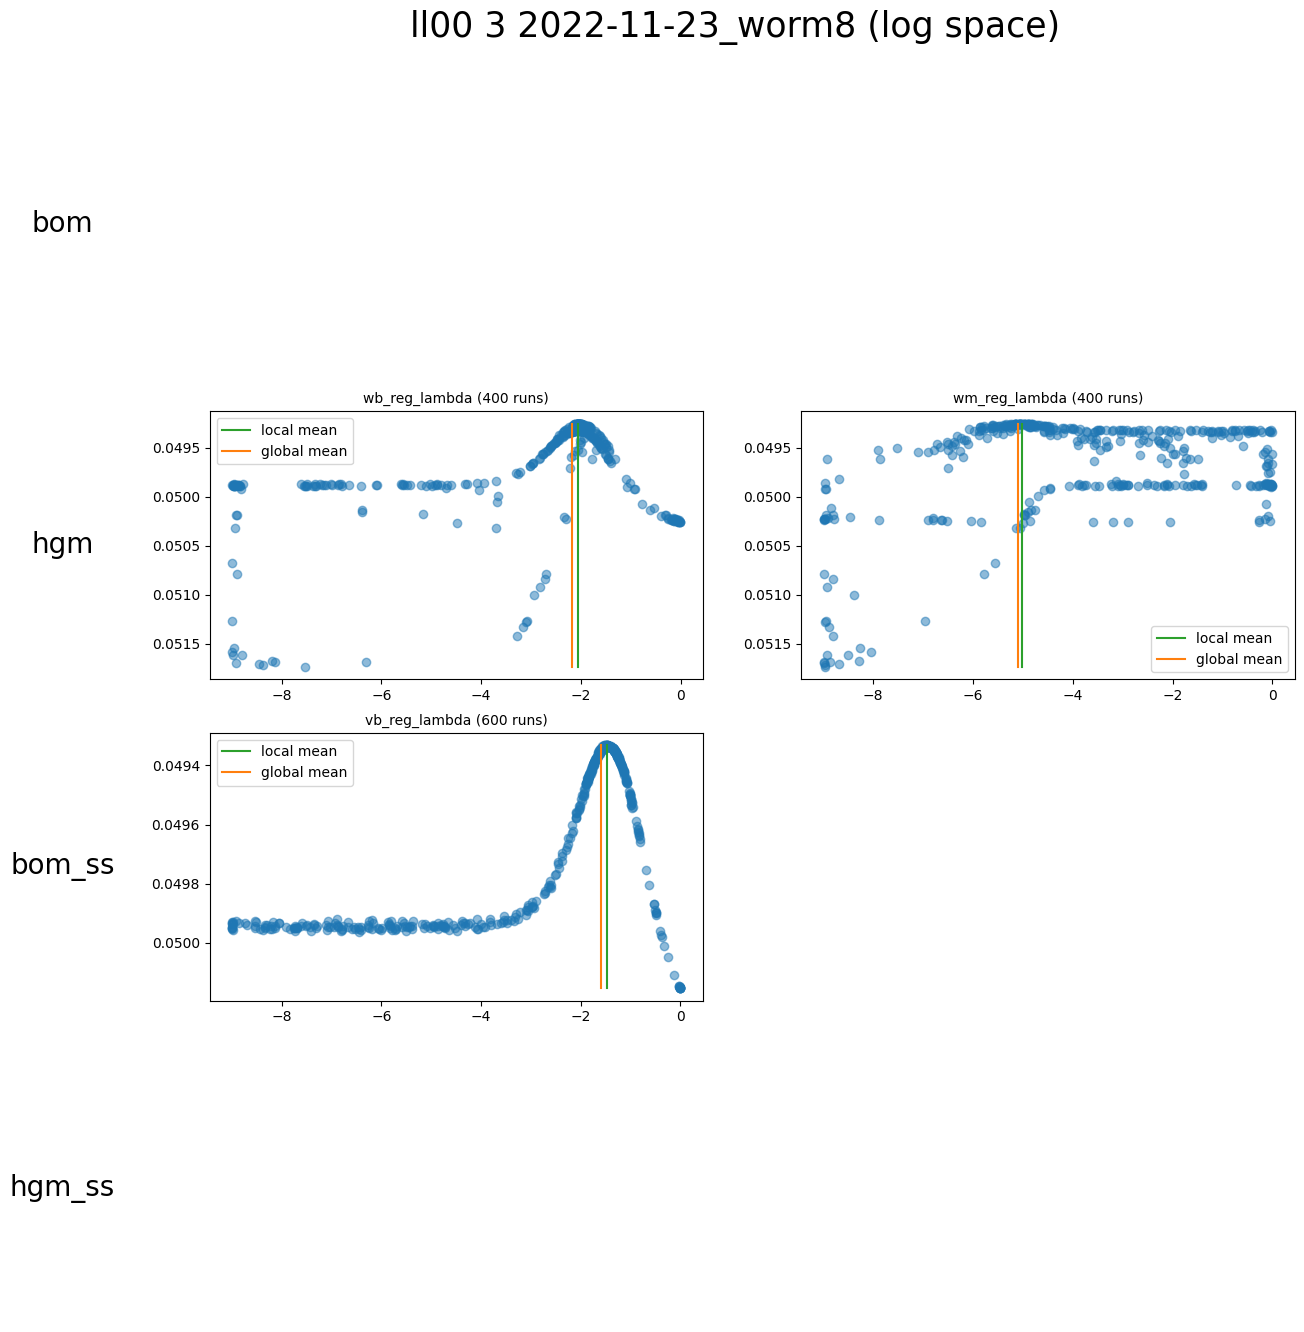

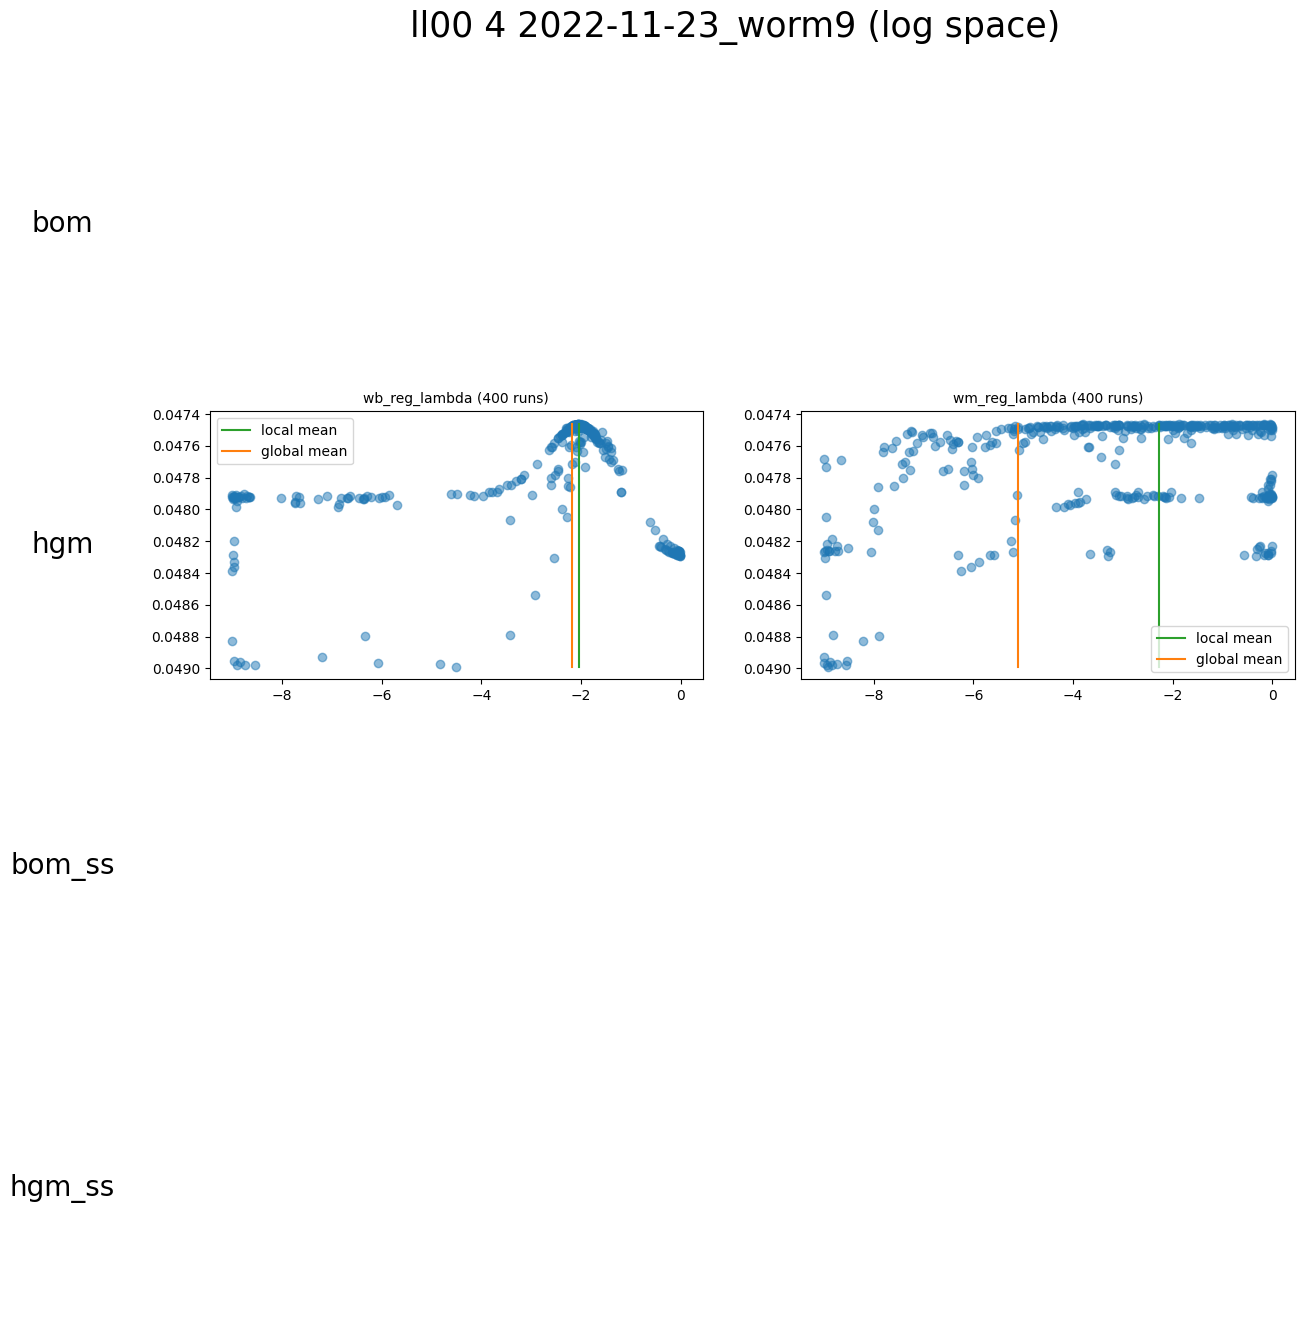

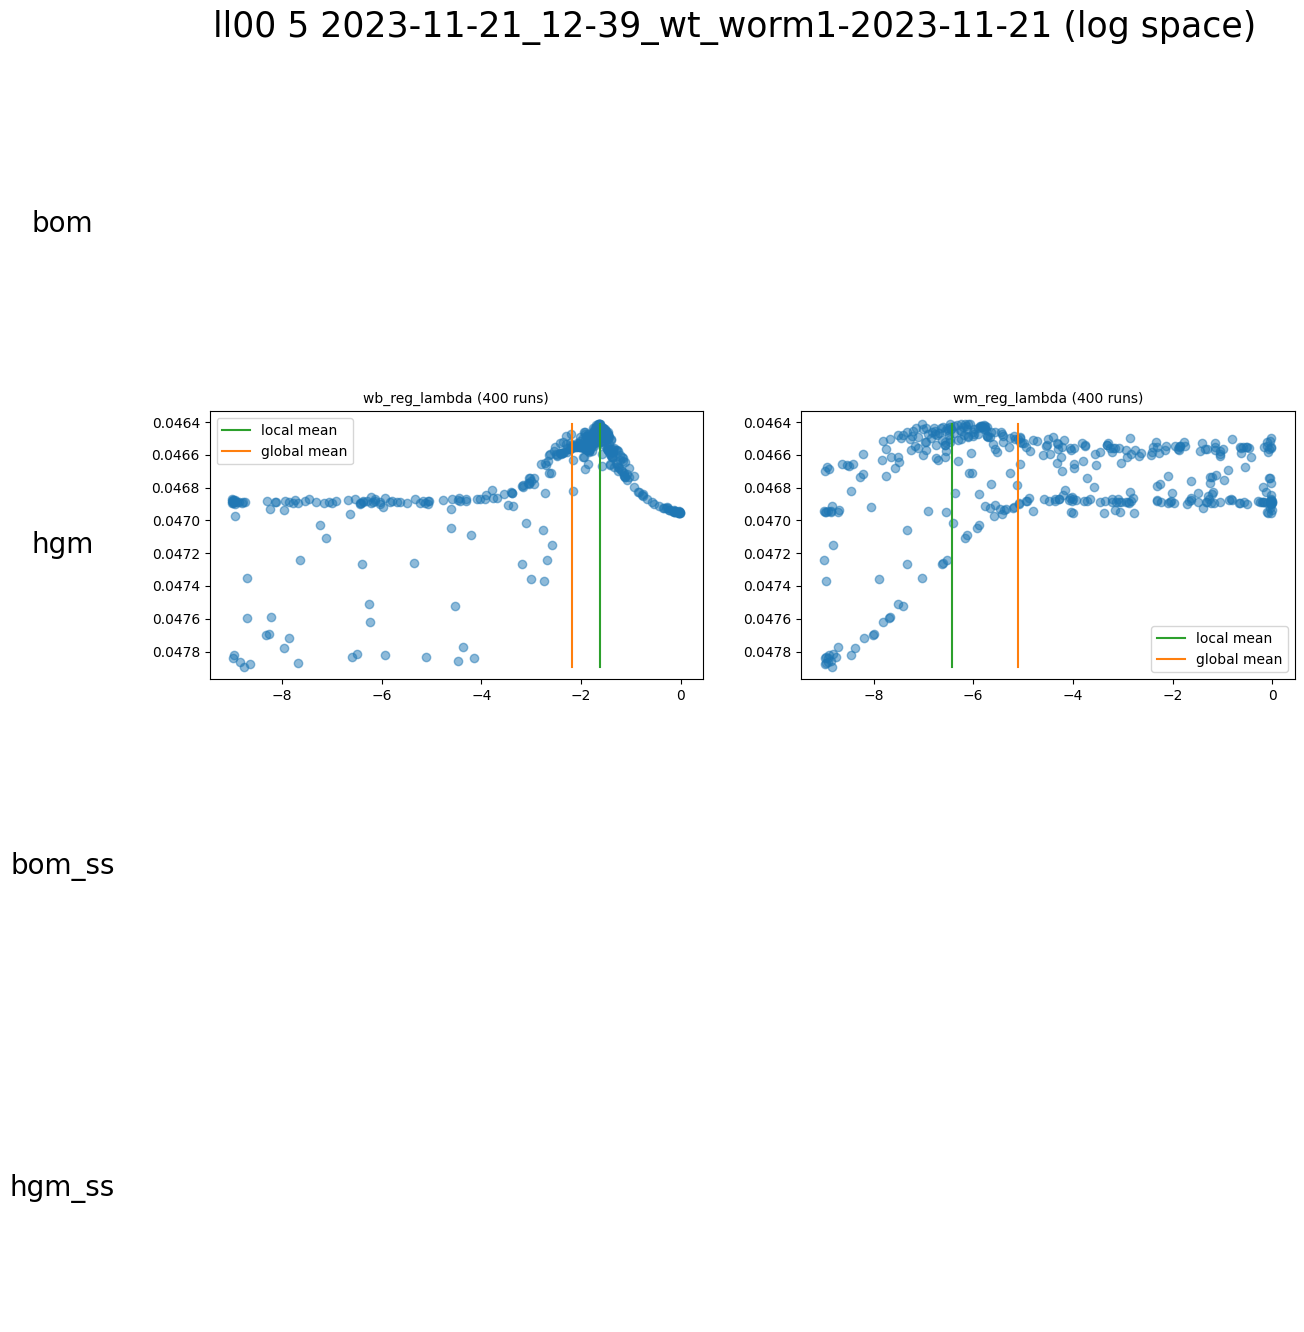

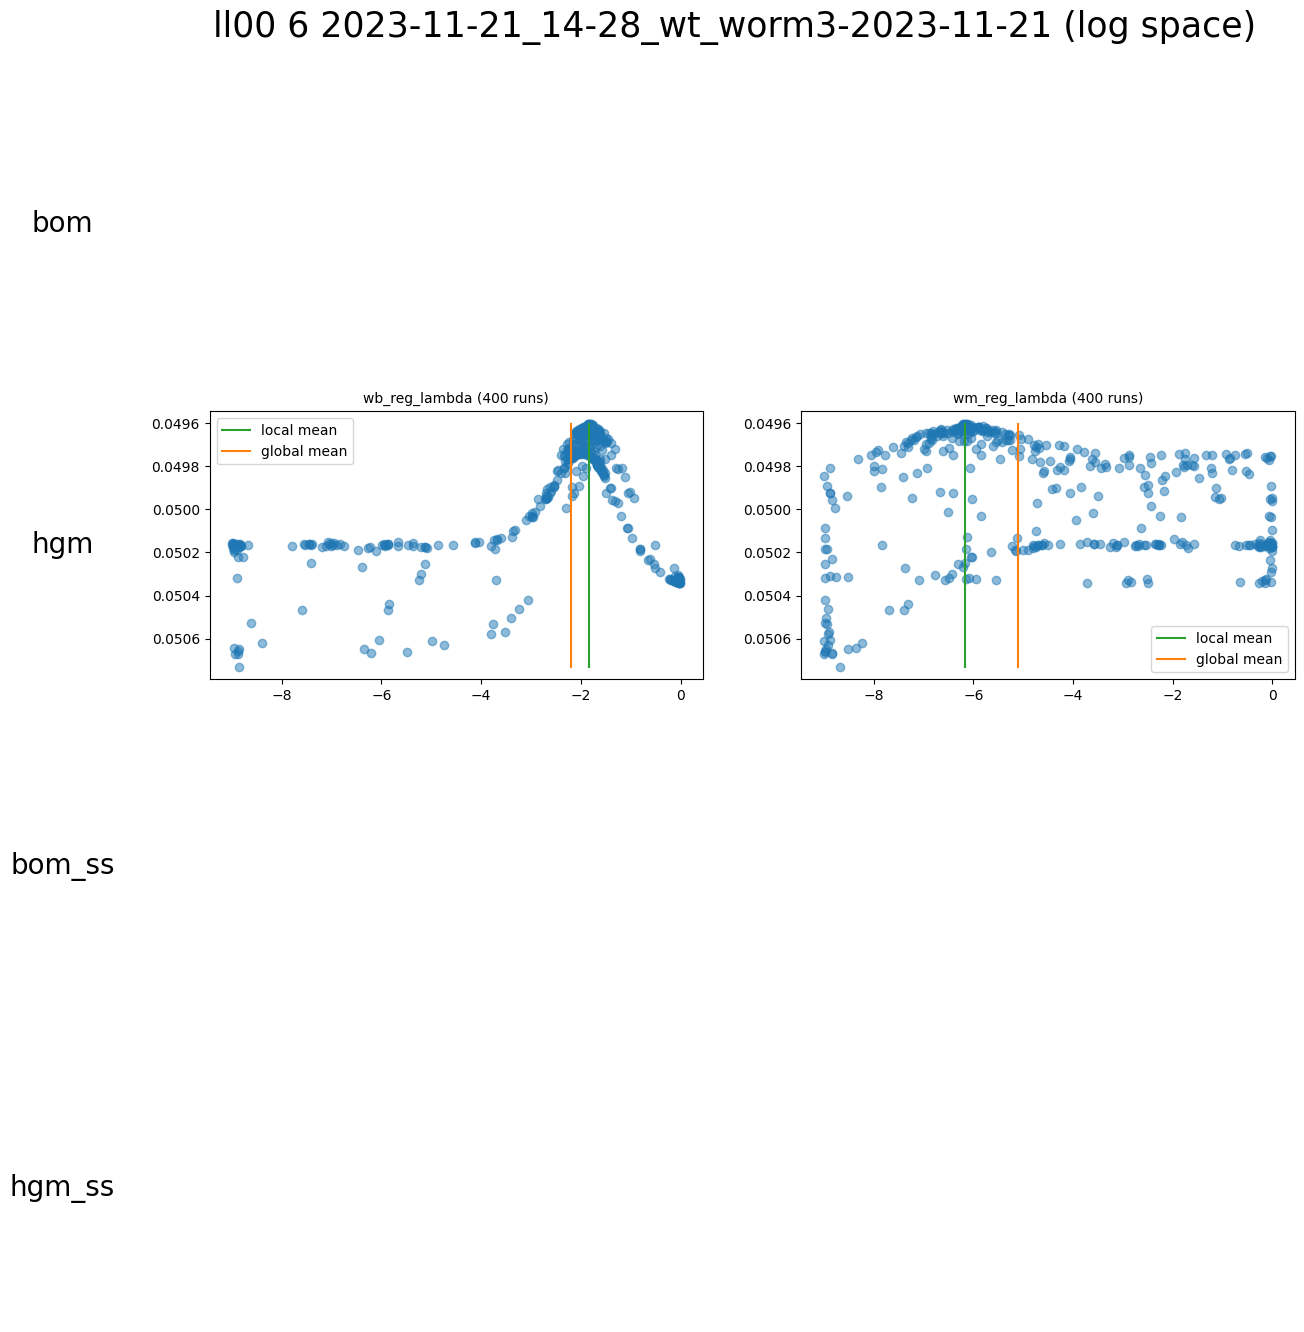

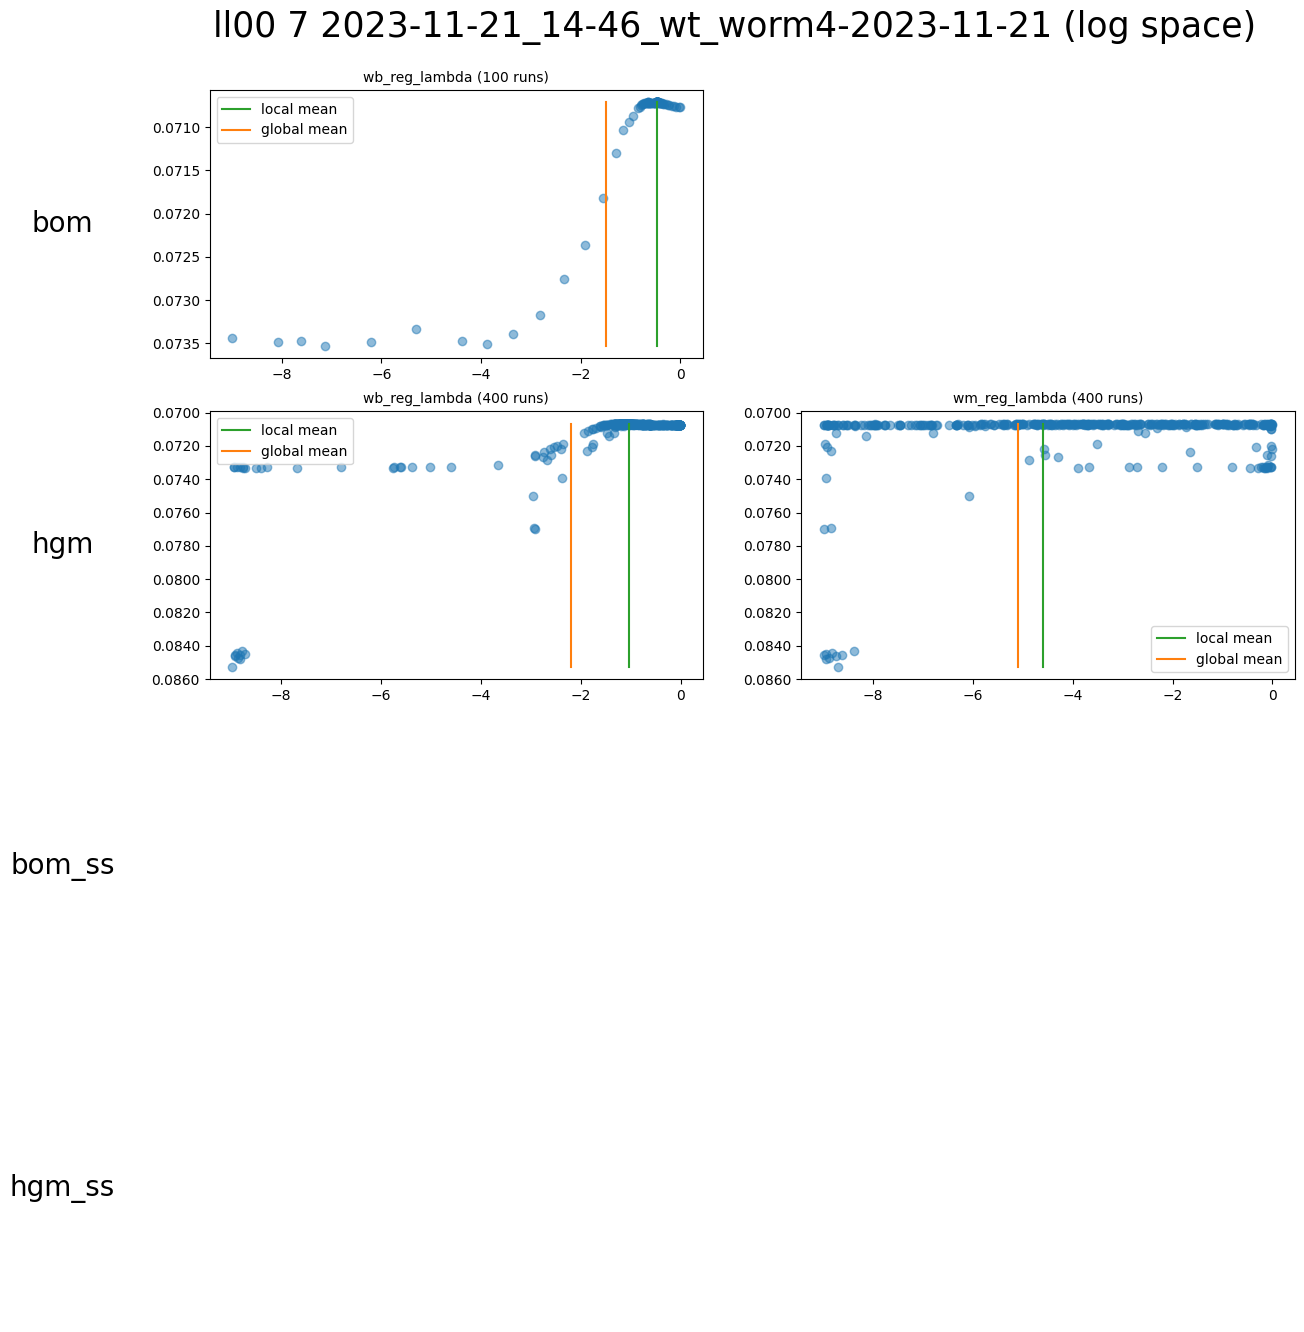

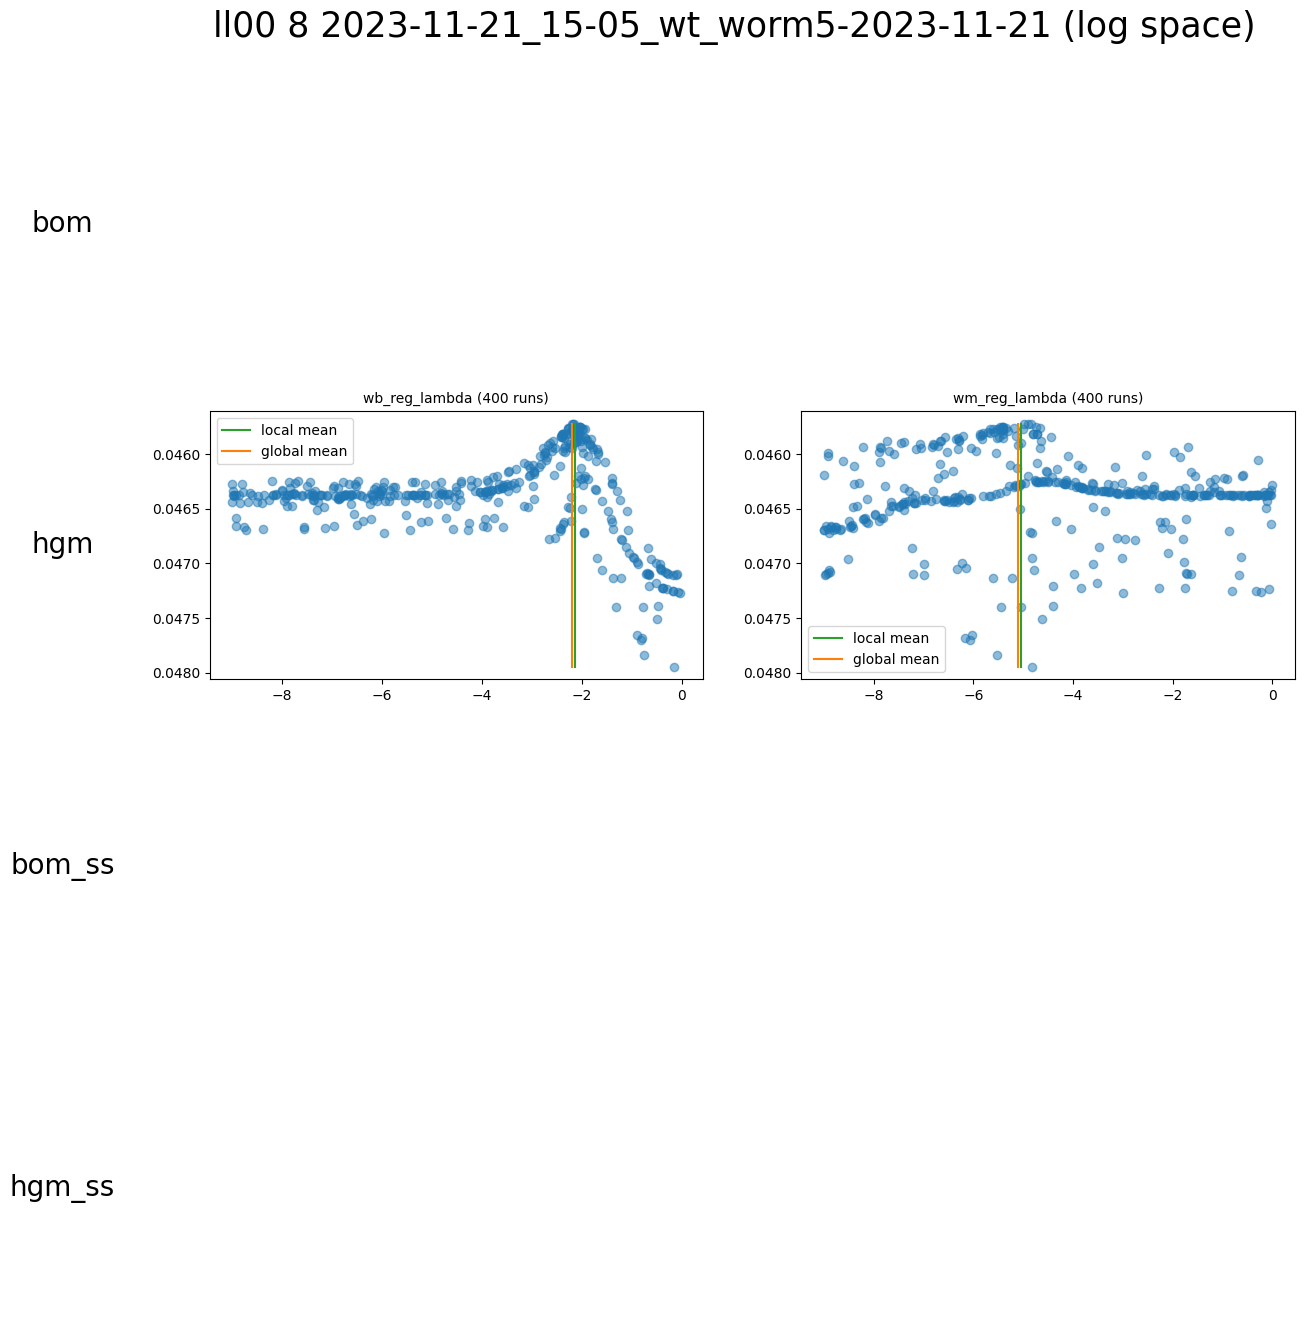

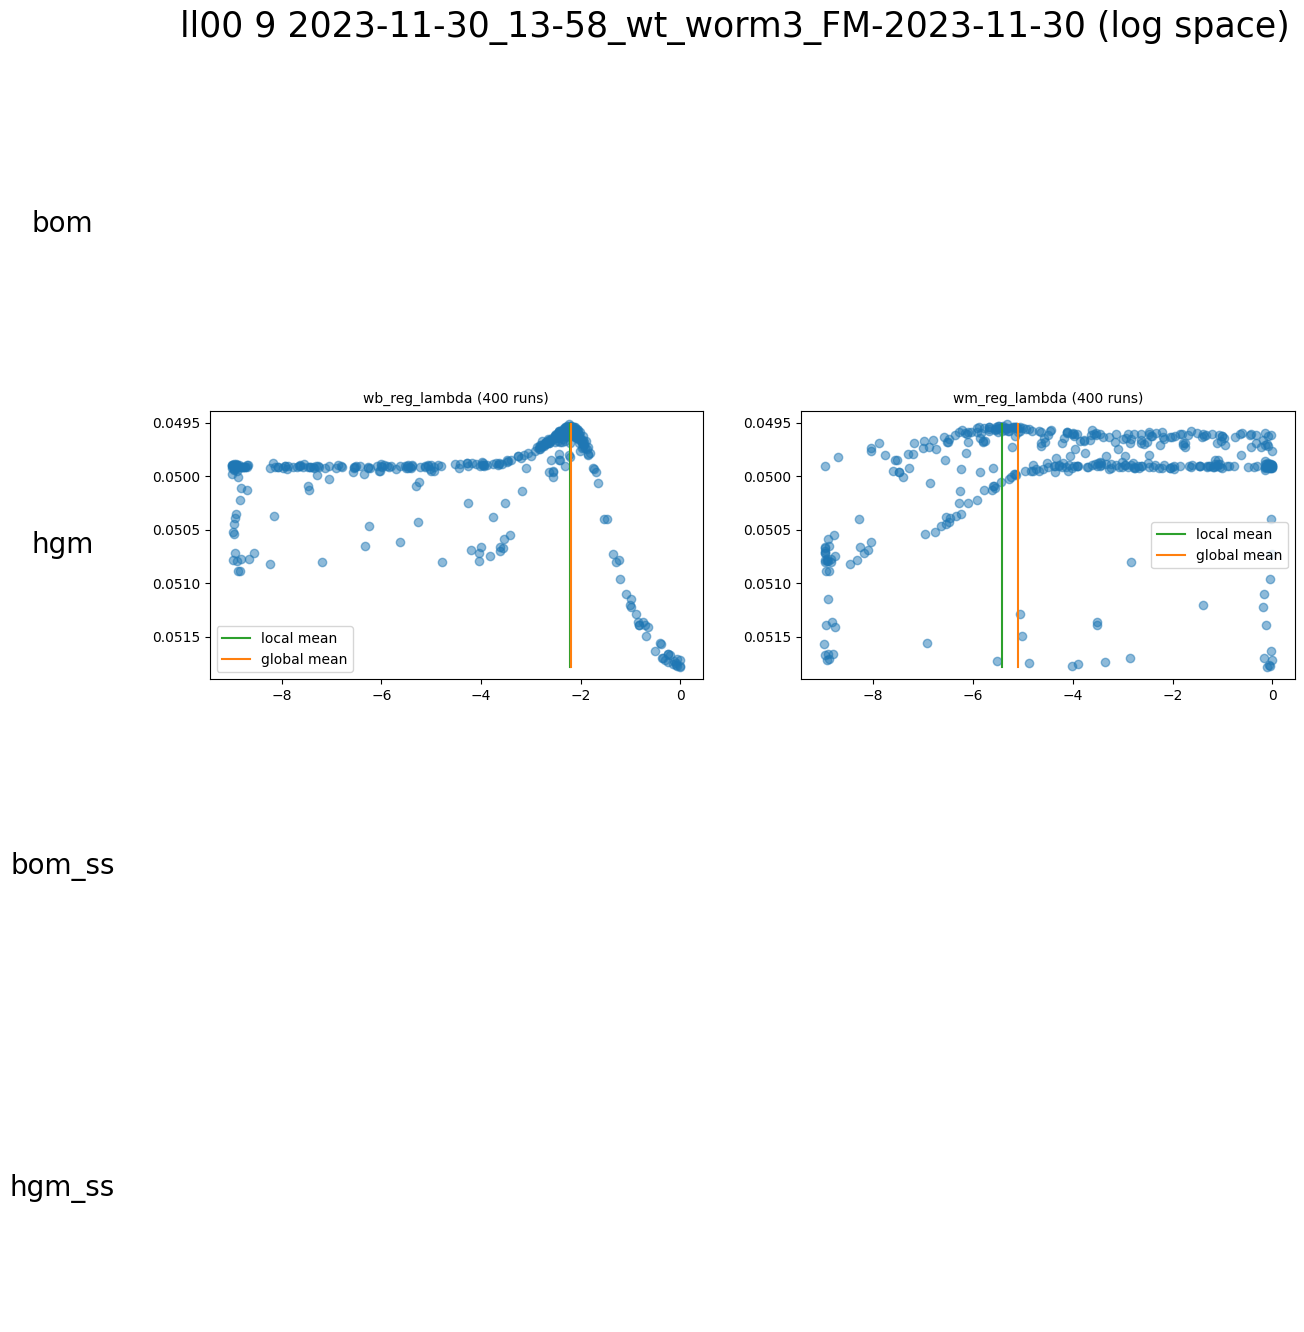

In [9]:
save = False
plot_utils.plot_hyperparams(hyperparams, None,
							ll='ll00', histograms=False, space='logarithmic',
							save_dirpath='../../out/plots/hyperparameters' if save else None)

In [10]:
with open('./hyperparams.pkl', 'wb') as file:
    pickle.dump(hyperparams, file)